# Energy data check: base-year data, IEA inputs and model results against IEA WEO 2025

In [1]:
# ---- paths and inputs: change here ----
import os
DATA_DIR      = '.'                                        # mset2_IPCC/Data (folder of this notebook)
SCENARIO      = 'IEA_CP'
RESULTS_DIR   = os.path.join('..','Results','archive_calibration_IEA_CP_20261125_0006')          # model results to compare
IEA_DIR       = os.path.join('Projection work','WEO2025 extended data')
IEA_SCENARIO  = 'Current Policies Scenario'
FIG_DIR       = 'energy_data_check_figures'                # only output folder: section 7 figures (PNG) and iea_comparison.csv

SCENARIO_FILE    = os.path.join(DATA_DIR, 'MSET_data', 'Scenarios', f'{SCENARIO}.xlsx')
VARIABLE_LIST    = os.path.join(DATA_DIR, 'MSET_data', 'Variable_list_MINDSET.xlsx')
POWER_IO_FILE    = os.path.join(DATA_DIR, 'MSET_data', 'Energy_emissions', 'power_generation_IO.csv')
IND_FILE         = os.path.join(DATA_DIR, 'GLORIA_db', 'IND_sparse.pkl')
ALL_FUELS_FILE   = os.path.join(DATA_DIR, 'Energy_db', 'ALL_FUELS.csv')
IEA_REGIONS_FILE = os.path.join(IEA_DIR, 'WEO2025_Extended_Data_Regions.csv')
IEA_SUPPLY_FILE  = os.path.join(IEA_DIR, 'WEO2025_Extended_Data_Supply_Refining_H2_Trade_Prices.csv')
IEA_INVEST_FILE  = os.path.join(IEA_DIR, 'WEO2025_Extended_Data_Investment.csv')

# comparison groups: name -> (model regions, IEA regions); World = sum of these
GROUPS = {'Africa':       (['AFR'], ['Africa']),
          'Middle East':  (['MEN'], ['Middle East']),
          'Europe':       (['EUR'], ['Europe']),
          'Eurasia':      (['EEA'], ['Eurasia']),
          'Americas':     (['NAM', 'LAC'], ['North America', 'Central and South America']),
          'Asia Pacific': (['EAS', 'SAS', 'SEP', 'AJN'], ['Asia Pacific'])}
# approximate single-region matches (tables and scorecards only)
PROXIES = {'EAS ~ China': (['EAS'], ['China']), 'SAS ~ India': (['SAS'], ['India']), 'SEP ~ SE Asia': (['SEP'], ['Southeast Asia'])}
# closest IEA region of each model region (buildings share table)
REGION_PROXY = {'AFR': 'Africa', 'MEN': 'Middle East', 'EUR': 'Europe', 'EEA': 'Eurasia', 'NAM': 'North America',
                'LAC': 'Central and South America', 'EAS': 'China', 'SAS': 'India', 'SEP': 'Southeast Asia', 'AJN': 'Japan'}
YEARS_IEA  = [2024, 2035, 2040, 2045, 2050]                # 2024 historical, later years IEA_SCENARIO
ROAD_SHARE = 0.9                                           # share of household refined petroleum that is road fuel

for p in [SCENARIO_FILE, VARIABLE_LIST, POWER_IO_FILE, IND_FILE, ALL_FUELS_FILE, RESULTS_DIR, IEA_REGIONS_FILE, IEA_SUPPLY_FILE, IEA_INVEST_FILE]:
    print('ok     ' if os.path.exists(p) else 'MISSING', p)

ok      .\MSET_data\Scenarios\IEA_CP.xlsx
ok      .\MSET_data\Variable_list_MINDSET.xlsx
ok      .\MSET_data\Energy_emissions\power_generation_IO.csv
ok      .\GLORIA_db\IND_sparse.pkl
ok      .\Energy_db\ALL_FUELS.csv
ok      ..\Results\archive_calibration_IEA_CP_20261125_0006
ok      Projection work\WEO2025 extended data\WEO2025_Extended_Data_Regions.csv
ok      Projection work\WEO2025 extended data\WEO2025_Extended_Data_Supply_Refining_H2_Trade_Prices.csv
ok      Projection work\WEO2025 extended data\WEO2025_Extended_Data_Investment.csv


In [2]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('ignore')

def show(df, title, fmt=None):
    print(title)
    display(df if fmt is None else df.apply(lambda s: s.map(lambda v: '' if pd.isna(v) else fmt.format(v))))

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def fuel_group(name):
    name = name.lower()
    if re.search('hard coal|lignite|coke', name): return 'Coal'
    if 'petroleum' in name: return 'Oil'
    if 'gas extraction' in name: return 'Gas'
    if 'electric power' in name: return 'Electricity'
    return 'Other'

sec = pd.read_excel(VARIABLE_LIST, sheet_name='P')
sec = pd.DataFrame({'TRAD_COMM': sec['Lfd_Nr'].astype(int), 'fuel': sec['Sector_names'].str.slice(0, 30),
                    'group': sec['Sector_names'].map(fuel_group)})
elec = str(sec.loc[sec['group'] == 'Electricity', 'TRAD_COMM'].iloc[0])
key = ['REG_imp', 'REG_exp', 'PROD_COMM', 'TRAD_COMM']

ind = pd.read_pickle(IND_FILE).reset_index().astype({'PROD_COMM': int, 'TRAD_COMM': int}).astype({'PROD_COMM': str})
fuels = pd.read_csv(ALL_FUELS_FILE, dtype={'PROD_COMM': str}).astype({'TRAD_COMM': int})
fuels['EJ'] = fuels['physical_value'] / 1e6
fuels = fuels.merge(sec, how='left', on='TRAD_COMM')

flows = fuels.loc[~fuels['PROD_COMM'].str.contains('FD'), key + ['EJ']].merge(ind[key + ['z_bp']], how='outer', on=key)
flows = flows.fillna({'EJ': 0, 'z_bp': 0}).merge(sec, how='left', on='TRAD_COMM')
flows = flows[flows['group'] != 'Other']

gen = pd.read_excel(SCENARIO_FILE, sheet_name='Power generation shares', skiprows=13)
gen19 = pd.DataFrame({'REG_imp': gen['Country ISO*'], 'tech': gen['Technology'], 'col': gen['Technology name*'],
                      'TWh': pd.to_numeric(gen[2019], errors='coerce').fillna(0)}).dropna(subset=['REG_imp'])
regions = sorted(fuels['REG_imp'].unique())

## 1. Energy use by region and fuel (ALL_FUELS, 2019)

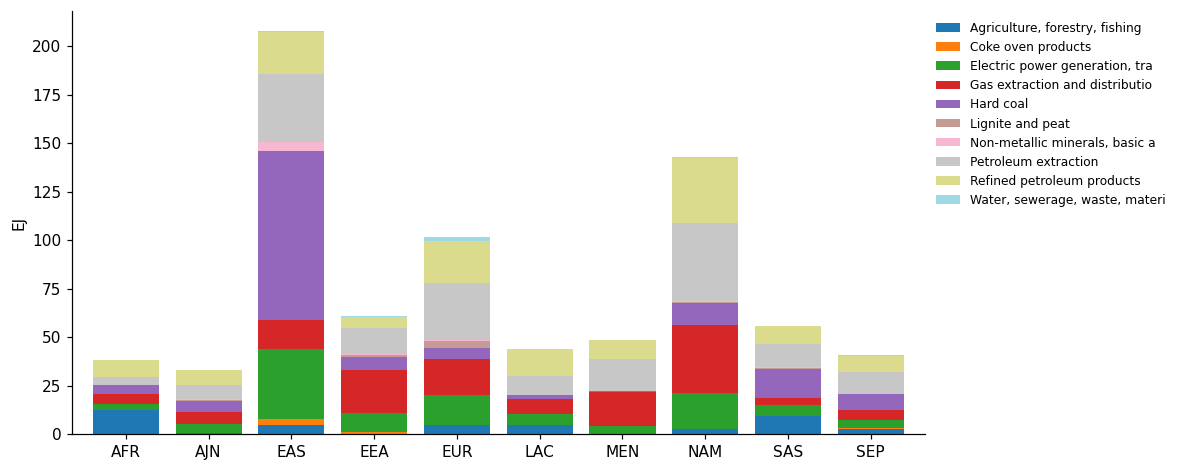

EJ, all users including final demand


REG_imp,AFR,AJN,EAS,EEA,EUR,LAC,MEN,NAM,SAS,SEP,WORLD
fuel,,,,,,,,,,,
"Agriculture, forestry, fishing",12.4,0.6,4.8,0.4,4.6,4.9,0.0,2.8,9.2,3.0,42.7
Coke oven products,0.0,0.1,3.2,0.9,0.2,0.1,0.0,0.1,0.2,0.2,4.9
"Electric power generation, tra",3.1,4.8,35.8,9.8,15.7,5.6,4.1,18.5,5.8,4.2,107.3
Gas extraction and distributio,5.2,5.8,15.1,22.4,18.6,7.7,17.8,35.0,3.6,5.1,136.4
Hard coal,4.7,5.7,86.9,6.4,5.4,1.8,0.4,11.2,15.0,8.1,145.5
Lignite and peat,0.0,0.4,0.1,1.2,3.7,0.0,0.0,0.7,0.4,0.3,6.8
"Non-metallic minerals, basic a",0.0,0.4,4.5,0.3,0.6,0.1,0.0,0.1,0.4,0.1,6.6
Petroleum extraction,4.3,7.5,35.3,13.5,29.2,9.8,16.8,40.6,11.8,11.0,179.8
Refined petroleum products,8.7,7.5,21.5,6.0,21.7,13.8,9.4,33.3,9.1,8.6,139.5


In [3]:
e1 = fuels.pivot_table(index='REG_imp', columns='fuel', values='EJ', aggfunc='sum', fill_value=0)
e1.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20', width=0.8)
plt.ylabel('EJ'); plt.xlabel(''); plt.xticks(rotation=0); plt.legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1)); plt.show()

t = e1.T; t['WORLD'] = t.sum(axis=1)
show(t, 'EJ, all users including final demand', '{:,.1f}')

## 2. Who uses the energy

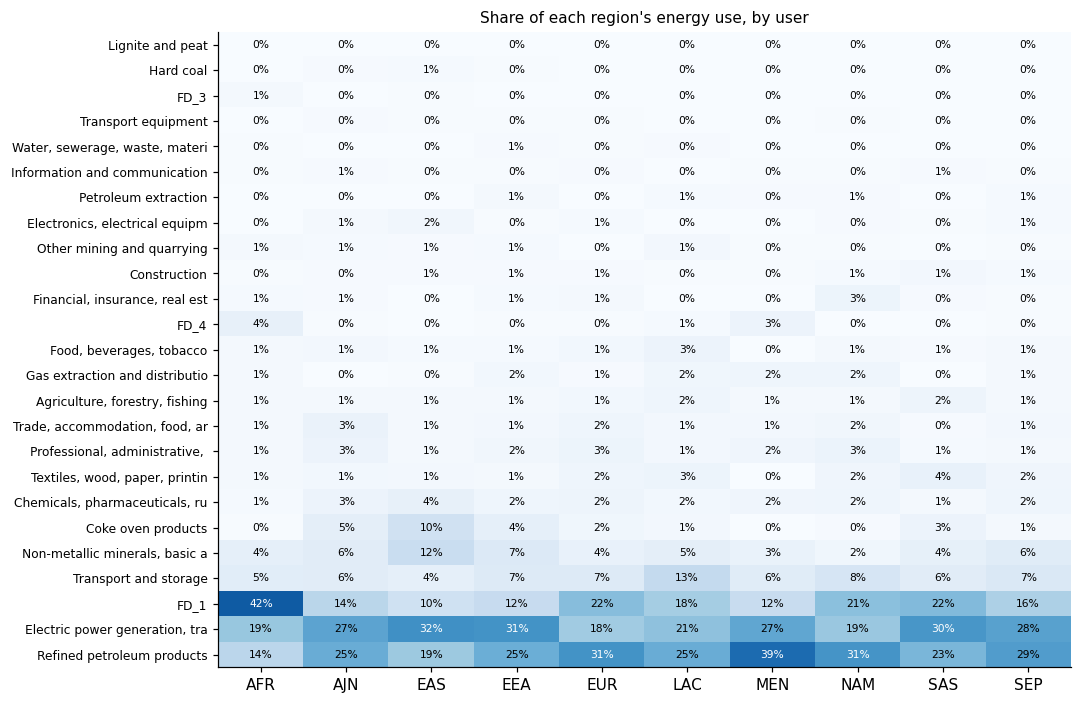

In [4]:
users = sec.assign(PROD_COMM=sec['TRAD_COMM'].astype(str))[['PROD_COMM', 'fuel']].rename(columns={'fuel': 'user'})
e2 = fuels.merge(users, how='left', on='PROD_COMM')
e2['user'] = e2['user'].fillna(e2['PROD_COMM'])
e2 = e2.pivot_table(index='user', columns='REG_imp', values='EJ', aggfunc='sum', fill_value=0)
e2 = e2 / e2.sum()
e2 = e2.loc[e2.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.imshow(e2.values, cmap='Blues', aspect='auto', vmin=0, vmax=0.5)
ax.set_xticks(range(e2.shape[1])); ax.set_xticklabels(e2.columns)
ax.set_yticks(range(e2.shape[0])); ax.set_yticklabels(e2.index, fontsize=8)
for i in range(e2.shape[0]):
    for j in range(e2.shape[1]):
        ax.text(j, i, f'{e2.values[i, j]:.0%}', ha='center', va='center', fontsize=7, color='white' if e2.values[i, j] > 0.3 else 'black')
ax.set_title("Share of each region's energy use, by user", fontsize=10); plt.show()

## 3. Price implied by money (IND) and energy (ALL_FUELS)

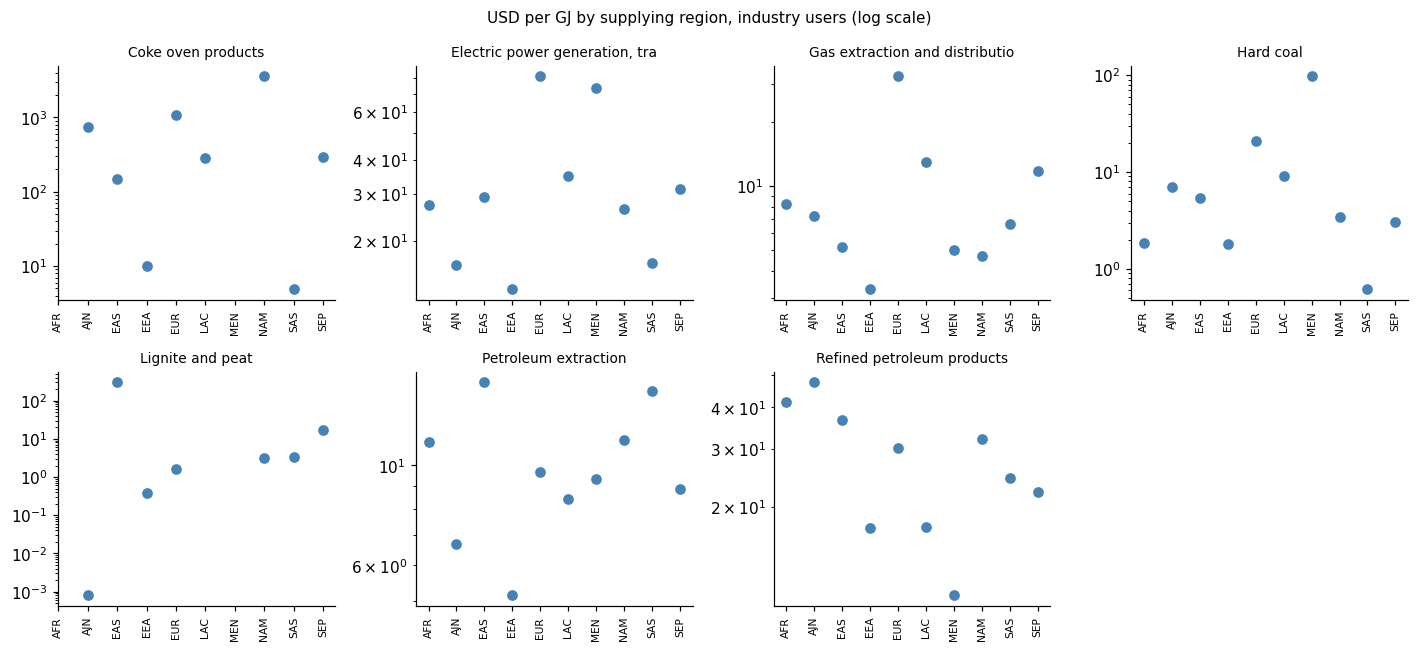

USD per GJ by supplying region (supply above 0.05 EJ)


REG_exp,AFR,AJN,EAS,EEA,EUR,LAC,MEN,NAM,SAS,SEP
fuel,,,,,,,,,,
Coke oven products,,742.9,148.3,9.9,"1,069.0",287.3,,"3,572.8",4.9,290.3
"Electric power generation, tra",27.2,16.4,29.2,13.3,81.3,34.8,73.6,26.3,16.6,31.2
Gas extraction and distributio,8.2,7.2,5.2,3.3,32.7,12.9,5.0,4.7,6.6,11.7
Hard coal,1.9,6.9,5.4,1.8,21.1,9.1,97.5,3.4,0.6,3.0
Lignite and peat,,0.0,300.1,0.4,1.7,,,3.1,3.2,16.9
Petroleum extraction,11.3,6.7,15.3,5.2,9.6,8.4,9.3,11.4,14.6,8.8
Refined petroleum products,41.6,47.6,36.6,17.3,30.1,17.5,10.8,32.2,24.5,22.2


USD per GJ paid by the electricity sector (use above 0.05 EJ)


REG_imp,AFR,AJN,EAS,EEA,EUR,LAC,MEN,NAM,SAS,SEP
fuel,,,,,,,,,,
"Electric power generation, tra",45.5,10.8,63.3,34.8,129.7,62.7,106.2,15.8,7.6,91.7
Gas extraction and distributio,2.3,2.7,3.5,1.3,17.1,6.0,1.6,4.6,1.6,4.9
Hard coal,0.9,1.5,2.4,0.5,9.4,2.3,7.4,1.5,0.6,2.2
Lignite and peat,,0.0,317.9,0.1,1.5,,,1.9,4.2,1.6
Petroleum extraction,,,,0.0,,1.6,0.0,,,
Refined petroleum products,2.5,0.2,36.6,7.0,28.1,2.1,1.9,0.0,23.7,11.5


In [5]:
pe = flows.groupby(['fuel', 'REG_exp'])[['z_bp', 'EJ']].sum()
pe['USD_per_GJ'] = pe['z_bp'] / 1e6 / pe['EJ']
pe = pe[pe['EJ'] > 0.05].reset_index()

names = sorted(pe['fuel'].unique())
fig, axes = plt.subplots(2, 4, figsize=(13, 6)); axes = axes.ravel()
for ax, f in zip(axes, names):
    d = pe[pe['fuel'] == f].set_index('REG_exp')['USD_per_GJ'].reindex(regions)
    ax.scatter(range(len(regions)), d.values, color='steelblue'); ax.set_yscale('log')
    ax.set_xticks(range(len(regions))); ax.set_xticklabels(regions, rotation=90, fontsize=7); ax.set_title(f, fontsize=9)
for ax in axes[len(names):]: ax.axis('off')
fig.suptitle('USD per GJ by supplying region, industry users (log scale)', fontsize=10); plt.tight_layout(); plt.show()

show(pe.pivot(index='fuel', columns='REG_exp', values='USD_per_GJ'), 'USD per GJ by supplying region (supply above 0.05 EJ)', '{:,.1f}')

pp = flows[flows['PROD_COMM'] == elec].groupby(['fuel', 'REG_imp'])[['z_bp', 'EJ']].sum()
pp['USD_per_GJ'] = pp['z_bp'] / 1e6 / pp['EJ']
show(pp[pp['EJ'] > 0.05]['USD_per_GJ'].unstack('REG_imp'), 'USD per GJ paid by the electricity sector (use above 0.05 EJ)', '{:,.1f}')

## 4. Flows present in one file and missing in the other

In [6]:
tot = flows.groupby(['fuel', 'REG_imp'])[['EJ', 'z_bp']].sum()
lost = flows[flows['z_bp'] == 0].groupby(['fuel', 'REG_imp'])['EJ'].sum().reindex(tot.index, fill_value=0)
t = (lost.map('{:.2f}'.format) + ' (' + (100 * lost / tot['EJ']).fillna(0).map('{:.0f}'.format) + '%)').unstack('REG_imp')
show(t, "Energy in ALL_FUELS with no money flow in IND: EJ (share of the fuel's industry use). The model shows none of this energy.")
print(f"World: {lost.sum():.1f} of {tot['EJ'].sum():.1f} EJ")

noen = flows[flows['EJ'] == 0].groupby(['fuel', 'REG_imp'])['z_bp'].sum().reindex(tot.index, fill_value=0) / 1e6
t = (noen.map('{:.1f}'.format) + ' (' + (100 * noen / (tot['z_bp'] / 1e6)).fillna(0).map('{:.0f}'.format) + '%)').unstack('REG_imp')
show(t, "Money flows in IND with no energy in ALL_FUELS: bn USD (share of the fuel's sales to industry). These purchases carry no energy or emissions.")

Energy in ALL_FUELS with no money flow in IND: EJ (share of the fuel's industry use). The model shows none of this energy.


REG_imp,AFR,AJN,EAS,EEA,EUR,LAC,MEN,NAM,SAS,SEP
fuel,,,,,,,,,,
Coke oven products,0.00 (1%),0.01 (5%),0.06 (2%),0.00 (0%),0.01 (4%),0.00 (2%),0.00 (0%),0.00 (5%),0.00 (0%),0.00 (1%)
"Electric power generation, tra",0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.01 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%)
Gas extraction and distributio,0.00 (0%),0.06 (1%),0.02 (0%),0.00 (0%),0.07 (1%),0.01 (0%),0.00 (0%),0.00 (0%),0.12 (4%),0.00 (0%)
Hard coal,0.00 (0%),0.22 (4%),3.11 (4%),0.10 (2%),0.32 (6%),0.03 (2%),0.00 (0%),0.24 (2%),0.13 (1%),0.16 (2%)
Lignite and peat,0.00 (0%),0.01 (1%),0.00 (1%),0.03 (2%),0.02 (0%),0.00 (3%),0.00 (100%),0.01 (1%),0.08 (18%),0.01 (2%)
Petroleum extraction,0.00 (0%),0.00 (0%),0.02 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%)
Refined petroleum products,0.00 (0%),0.01 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.00 (0%),0.91 (6%),0.00 (0%),0.00 (0%)


World: 5.8 of 608.4 EJ
Money flows in IND with no energy in ALL_FUELS: bn USD (share of the fuel's sales to industry). These purchases carry no energy or emissions.


REG_imp,AFR,AJN,EAS,EEA,EUR,LAC,MEN,NAM,SAS,SEP
fuel,,,,,,,,,,
Coke oven products,0.2 (0%),0.0 (0%),0.1 (0%),0.0 (0%),0.1 (0%),0.1 (0%),0.0 (0%),283.4 (84%),1.0 (56%),32.6 (84%)
"Electric power generation, tra",0.0 (0%),1.3 (2%),0.0 (0%),0.1 (0%),0.0 (0%),0.0 (0%),0.1 (0%),0.0 (0%),0.0 (0%),0.2 (0%)
Gas extraction and distributio,0.2 (1%),0.0 (0%),0.0 (0%),0.3 (1%),0.0 (0%),0.0 (0%),0.1 (0%),0.0 (0%),0.0 (0%),0.1 (0%)
Hard coal,0.1 (1%),0.0 (0%),0.1 (0%),0.0 (0%),0.1 (0%),0.5 (3%),1.1 (14%),0.2 (1%),0.0 (0%),1.9 (7%)
Lignite and peat,2.8 (52%),0.0 (100%),4.1 (12%),0.0 (0%),0.1 (1%),5.8 (65%),0.1 (100%),0.8 (39%),0.1 (5%),0.6 (55%)
Petroleum extraction,14.9 (30%),0.4 (0%),0.0 (0%),0.6 (2%),41.8 (18%),1.3 (2%),0.9 (1%),42.7 (8%),7.1 (7%),23.5 (30%)
Refined petroleum products,0.0 (0%),0.0 (0%),0.0 (0%),0.0 (0%),0.0 (0%),0.0 (0%),0.0 (0%),0.0 (0%),0.0 (0%),0.0 (0%)


## 5. Power sector against IEA 2019

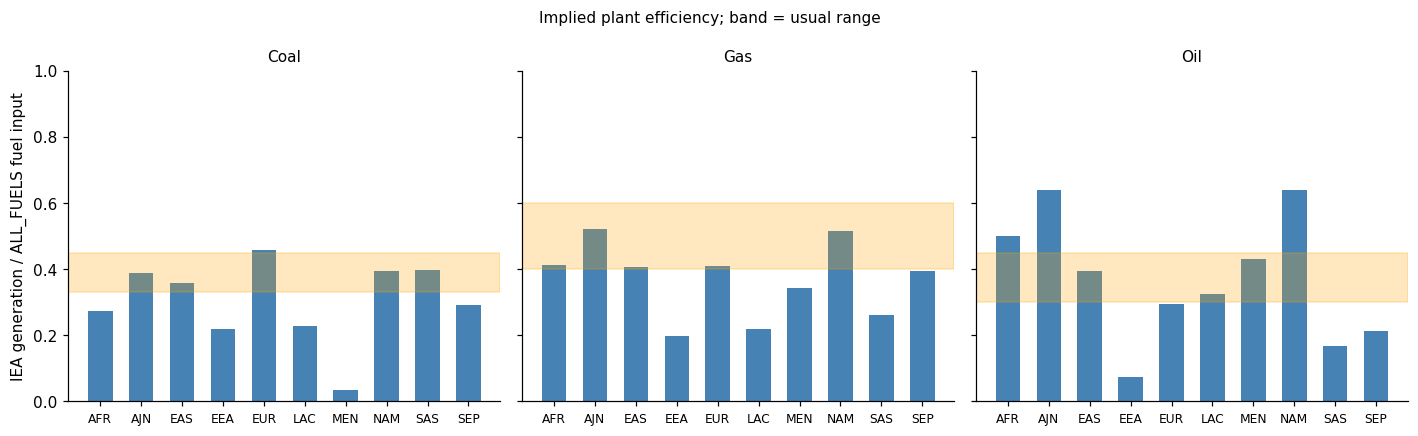

Implied efficiency (IEA generation / fuel input)


group,Coal,Gas,Oil
REG_imp,,,
AFR,0.27 (0.9 / 3.1 EJ),0.41 (1.2 / 3.0 EJ),0.50 (0.3 / 0.6 EJ)
AJN,0.39 (1.6 / 4.2 EJ),0.52 (1.7 / 3.3 EJ),0.64 (0.3 / 0.5 EJ)
EAS,0.36 (19.1 / 53.2 EJ),0.41 (1.6 / 4.0 EJ),0.39 (0.2 / 0.5 EJ)
EEA,0.22 (0.9 / 4.2 EJ),0.20 (2.4 / 12.0 EJ),0.07 (0.0 / 0.6 EJ)
EUR,0.46 (2.9 / 6.3 EJ),0.41 (2.5 / 6.2 EJ),0.29 (0.2 / 0.8 EJ)
LAC,0.23 (0.2 / 1.0 EJ),0.22 (0.8 / 3.8 EJ),0.32 (0.4 / 1.4 EJ)
MEN,0.04 (0.0 / 0.2 EJ),0.34 (2.9 / 8.6 EJ),0.43 (1.3 / 3.1 EJ)
NAM,0.39 (4.3 / 10.8 EJ),0.52 (6.9 / 13.3 EJ),0.64 (0.3 / 0.4 EJ)
SAS,0.40 (4.8 / 12.2 EJ),0.26 (0.5 / 1.8 EJ),0.17 (0.1 / 0.5 EJ)


Electricity supplied (ALL_FUELS) against IEA generation


,ALL_FUELS_EJ,IEA_EJ,ratio
AFR,3.13,3.05,1.03
AJN,4.84,4.88,0.99
EAS,35.80,30.62,1.17
EEA,9.87,4.99,1.98
EUR,15.63,14.08,1.11
LAC,5.55,4.85,1.14
MEN,3.96,4.49,0.88
NAM,18.57,19.10,0.97
SAS,5.80,6.86,0.85
SEP,4.15,4.00,1.04


In [7]:
pw = fuels[(fuels['PROD_COMM'] == elec) & fuels['group'].isin(['Coal', 'Gas', 'Oil'])].groupby(['REG_imp', 'group'])['EJ'].sum().rename('input_EJ')
ge = (gen19[gen19['tech'].isin(['Coal', 'Gas', 'Oil'])].groupby(['REG_imp', 'tech'])['TWh'].sum() * 0.0036).rename('generation_EJ')
ge.index.names = ['REG_imp', 'group']
eff = pd.concat([ge, pw], axis=1).reset_index()
eff['efficiency'] = eff['generation_EJ'] / eff['input_EJ']
band = {'Coal': (0.33, 0.45), 'Gas': (0.40, 0.60), 'Oil': (0.30, 0.45)}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, g in zip(axes, band):
    d = eff[eff['group'] == g].set_index('REG_imp')['efficiency'].reindex(regions)
    ax.bar(regions, d.values, color='steelblue', width=0.6); ax.axhspan(*band[g], color='orange', alpha=0.25)
    ax.set_ylim(0, 1); ax.set_title(g, fontsize=10); ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('IEA generation / ALL_FUELS fuel input')
fig.suptitle('Implied plant efficiency; band = usual range', fontsize=10); plt.tight_layout(); plt.show()

eff['value'] = eff.apply(lambda r: f"{r['efficiency']:.2f} ({r['generation_EJ']:.1f} / {r['input_EJ']:.1f} EJ)", axis=1)
show(eff.pivot(index='REG_imp', columns='group', values='value'), 'Implied efficiency (IEA generation / fuel input)')

el = pd.concat([fuels[fuels['group'] == 'Electricity'].groupby('REG_exp')['EJ'].sum().rename('ALL_FUELS_EJ'),
                (gen19.groupby('REG_imp')['TWh'].sum() * 0.0036).rename('IEA_EJ')], axis=1)
el['ratio'] = el['ALL_FUELS_EJ'] / el['IEA_EJ']
show(el, 'Electricity supplied (ALL_FUELS) against IEA generation', '{:,.2f}')

## 6. Electricity sector inputs: IND against the IEA mix

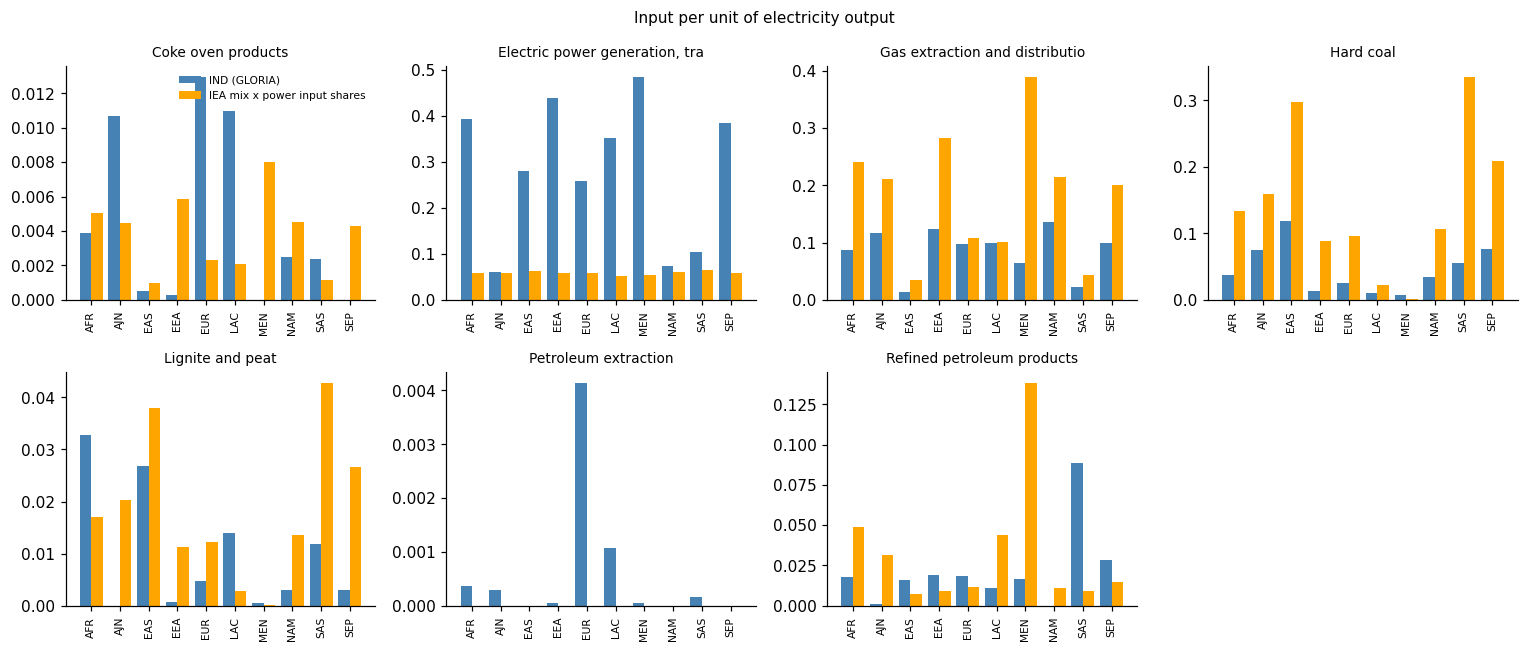

IEA mix x power input shares, as a multiple of the IND coefficient


REG_imp,AFR,AJN,EAS,EEA,EUR,LAC,MEN,NAM,SAS,SEP
fuel,,,,,,,,,,
Coke oven products,1.3,0.4,1.9,23.1,0.2,0.2,,1.8,0.5,395.4
"Electric power generation, tra",0.1,0.9,0.2,0.1,0.2,0.1,0.1,0.8,0.6,0.2
Gas extraction and distributio,2.8,1.8,2.6,2.3,1.1,1.0,6.0,1.6,1.9,2.0
Hard coal,3.7,2.1,2.5,6.7,3.9,2.3,0.1,3.1,6.1,2.8
Lignite and peat,0.5,361.7,1.4,16.3,2.6,0.2,0.2,4.6,3.6,9.0
Petroleum extraction,0.0,0.0,,0.0,0.0,0.0,0.0,,0.0,0.0
Refined petroleum products,2.7,32.4,0.4,0.5,0.6,3.9,8.2,,0.1,0.5


IEA generation mix, 2019


REG_imp,AFR,AJN,EAS,EEA,EUR,LAC,MEN,NAM,SAS,SEP
tech,,,,,,,,,,
Bio,0.3%,2.3%,1.6%,0.0%,5.0%,5.5%,0.0%,1.4%,1.8%,3.0%
Coal,28.1%,33.4%,62.3%,18.5%,20.3%,4.6%,0.2%,22.3%,70.4%,43.8%
Gas,40.4%,35.3%,5.4%,47.3%,17.9%,17.0%,65.5%,36.0%,6.7%,33.4%
Hydro,16.8%,8.3%,14.6%,17.6%,16.1%,52.9%,1.5%,12.2%,8.4%,14.8%
Nuclear,1.2%,7.6%,5.0%,15.1%,21.9%,1.7%,1.7%,17.5%,4.1%,0.0%
Oil,9.9%,6.0%,0.6%,0.9%,1.6%,9.1%,30.0%,1.4%,1.1%,2.2%
PV,1.1%,5.8%,4.0%,0.2%,5.2%,3.1%,1.0%,2.6%,3.8%,2.0%
Wind,2.2%,1.2%,6.5%,0.3%,11.9%,6.1%,0.2%,6.7%,3.7%,0.8%


In [8]:
pio = pd.read_csv(POWER_IO_FILE, index_col=0)
pio.index.name = 'TRAD_COMM'
pio = pio.reset_index().melt(id_vars='TRAD_COMM', var_name='col', value_name='input_share')
mix = gen19.groupby(['REG_imp', 'col'], as_index=False)['TWh'].sum()
mix['share'] = mix['TWh'] / mix.groupby('REG_imp')['TWh'].transform('sum')
mw = mix.merge(pio, on='col')
mw = (mw['share'] * mw['input_share']).groupby([mw['REG_imp'], mw['TRAD_COMM']]).sum().rename('IEA mix x power input shares')
gl = ind[ind['PROD_COMM'] == elec].groupby(['REG_imp', 'TRAD_COMM'])['a_bp'].sum().rename('IND (GLORIA)')
cmp = pd.concat([gl, mw], axis=1).fillna(0).reset_index().merge(sec, on='TRAD_COMM')
cmp = cmp[cmp['group'] != 'Other']

names = sorted(cmp['fuel'].unique())
fig, axes = plt.subplots(2, 4, figsize=(14, 6)); axes = axes.ravel(); x = np.arange(len(regions))
for ax, f in zip(axes, names):
    d = cmp[cmp['fuel'] == f].set_index('REG_imp').reindex(regions)
    ax.bar(x - 0.2, d['IND (GLORIA)'], 0.4, color='steelblue', label='IND (GLORIA)')
    ax.bar(x + 0.2, d['IEA mix x power input shares'], 0.4, color='orange', label='IEA mix x power input shares')
    ax.set_xticks(x); ax.set_xticklabels(regions, rotation=90, fontsize=7); ax.set_title(f, fontsize=9)
for ax in axes[len(names):]: ax.axis('off')
axes[0].legend(frameon=False, fontsize=7); fig.suptitle('Input per unit of electricity output', fontsize=10); plt.tight_layout(); plt.show()

cmp['ratio'] = cmp['IEA mix x power input shares'] / cmp['IND (GLORIA)'].replace(0, np.nan)
show(cmp.pivot(index='fuel', columns='REG_imp', values='ratio'), 'IEA mix x power input shares, as a multiple of the IND coefficient', '{:,.1f}')

m = gen19.groupby(['tech', 'REG_imp'])['TWh'].sum().unstack('REG_imp')
show(m / m.sum(), 'IEA generation mix, 2019', '{:.1%}')

## 7. Model results against IEA WEO 2025

Model: `RESULTS_DIR`. IEA: historical 2024 and `IEA_SCENARIO` for 2035-2050. Regions are compared in the groups set at the top (`GROUPS`); `PROXIES` are approximate.

| Indicator | Model measure |
|---|---|
| Electricity generation | electricity sold by the supplying region, all users and final demand |
| Power sector inputs | fuel bought by the electricity sector |
| Total energy supply | coal and gas: all use except the fuel sector's own; oil: refined products and crude used outside refining |
| Total final consumption | use by non-energy sectors and final demand; `Coal incl. coke ovens` also counts the coal and lignite bought by the coke-oven sector (not the coke itself) |
| Buildings | households and service sectors |
| Transport | transport sector, plus `ROAD_SHARE` of household refined petroleum for oil |
| Industry | mining, manufacturing, water and construction |
| CO2 | `qPollutant` plus cumulated `deltaPollutant` of the emissions files (sectors only, no household emissions) |
| Production | fuel supplied by the region (`REG_exp`), all users and final demand, own use excluded |
| GDP | `gdp_base`, 2024 = 1 |

In [9]:
import glob
C_MODEL, C_IEA = '#eb6834', '#2a78d6'
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name): fig.savefig(os.path.join(FIG_DIR, re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_') + '.png'), dpi=200, bbox_inches='tight')
P = pd.read_excel(VARIABLE_LIST, sheet_name='P'); pname = P.set_index('Lfd_Nr')['Sector_names']
def codes(pat): return [int(c) for c, n in pname.items() if re.search(pat, n, re.I)]
COAL, COKE, CRUDE, OILP, GAS, ELEC = codes('hard coal|lignite'), codes('coke oven'), codes('petroleum extraction'), codes('refined petroleum'), codes('gas extraction'), codes('electric power')
ENERGY = COAL + COKE + CRUDE + OILP + GAS + ELEC
TRANSPORT, SERVICES = codes('^transport and storage'), codes('^trade|^information|^financial|^professional')
INDUSTRY = [int(c) for c in pname.index if int(c) not in ENERGY + TRANSPORT + SERVICES + codes('^agriculture')]

def read_years(pattern):
    out = []
    for f in sorted(glob.glob(os.path.join(RESULTS_DIR, pattern))):
        d = pd.read_parquet(f); d['year'] = int(re.search(r'(\d{4})\.parquet$', f).group(1)); out.append(d)
    return pd.concat(out, ignore_index=True)

ef  = read_years(f'results_file_long_{SCENARIO}_energy_flows_[0-9]*.parquet').dropna(subset=['fuel_use']).astype({'PROD_COMM': int, 'TRAD_COMM': int})
efd = read_years(f'results_file_long_{SCENARIO}_energy_flows_fd_[0-9]*.parquet').dropna(subset=['fuel_use']).astype({'TRAD_COMM': int})
em  = read_years(f'emissions_{SCENARIO}_[0-9]*.parquet')
r0  = pd.read_csv(os.path.join(RESULTS_DIR, f'results_file_long_{SCENARIO}_0.csv'), usecols=['REG_imp', 'PROD_COMM', 'year', 'gdp_base', 'dk_exog'])

def by(d, region='REG_imp', col='fuel_use', scale=1e-6):          # region x year
    return d.groupby([region, 'year'])[col].sum().mul(scale).unstack('year').fillna(0)
def plus(*a):
    out = a[0]
    for x in a[1:]: out = out.add(x, fill_value=0)
    return out
def groups(w, side):                                               # side 0: model regions, 1: IEA regions
    if side == 0: w = w.reindex([r for v in GROUPS.values() for r in v[0]]).fillna(0)
    g = pd.DataFrame({k: w.reindex(v[side]).sum(min_count=len(v[side])) for k, v in GROUPS.items()}).T
    g.loc['World'] = g.sum(min_count=len(g))
    for k, v in PROXIES.items(): g.loc[k] = w.reindex(v[side]).sum(min_count=len(v[side]))
    return g

iea_raw = pd.read_csv(IEA_REGIONS_FILE); iea_raw = iea_raw[iea_raw['SCENARIO'].isin(['Historical', IEA_SCENARIO])]
def iea_w(category, flow, product, raw=iea_raw):                   # IEA region x year
    d = raw[(raw['CATEGORY'] == category) & (raw['FLOW'] == flow) & raw['PRODUCT'].isin(np.atleast_1d(product))]
    return d.assign(YEAR=d['YEAR'].astype(int)).groupby(['REGION', 'YEAR'])['VALUE'].sum().unstack('YEAR')
def iea(category, flow, product, scale=1.0):
    return groups(iea_w(category, flow, product) * scale, 1).reindex(columns=YEARS_IEA)

rows = []
def add(indicator, item, unit, model, iea_g, index_year=None):
    m = groups(model, 0)
    if index_year: m = m.div(m[index_year], axis=0); iea_g = iea_g.div(iea_g[index_year], axis=0)
    d = pd.concat([m.stack(dropna=False).rename('model'), iea_g.stack(dropna=False).rename('IEA')], axis=1).reset_index()
    d.columns = ['group', 'year', 'model', 'IEA']
    rows.append(d.assign(indicator=indicator, item=item, unit=unit))

T,  U  = (lambda c: ef['TRAD_COMM'].isin(c)),  (lambda c: ef['PROD_COMM'].isin(c))
Tf, HH = (lambda c: efd['TRAD_COMM'].isin(c)), efd['FD'] == 'FD_1'
EJ = 1e-3                                                          # IEA PJ -> EJ

### 7.1 Scenario inputs against IEA

Generation by technology in the `Power generation shares` sheet, power investment and the buildings electricity share.

In [10]:
gy = [c for c in gen.columns if isinstance(c, (int, np.integer))]
tech = {'Coal': 'Coal: unabated', 'Gas': 'Natural gas: unabated', 'Oil': 'Oil', 'Nuclear': 'Nuclear', 'Hydro': 'Hydro',
        'PV': 'Solar PV', 'Wind': 'Wind', 'Bio': 'Modern bioenergy and renewable waste'}
g = gen.dropna(subset=['Country ISO*'])
print('technologies in the sheet without an IEA match:', sorted(set(g['Technology']) - set(tech)))
def sheet(d):
    w = d.groupby('Country ISO*')[gy].sum(); w.columns = [int(c) for c in w.columns]; w.columns.name = 'year'; return w
add('Input: generation', 'Total', 'TWh', sheet(g), iea('Energy', 'Electricity generation', 'Total'))
for k, p in tech.items():
    add('Input: generation', k, 'TWh', sheet(g[g['Technology'] == k]), iea('Energy', 'Electricity generation', p))

# power investment, bn USD per year (sheet: thousand USD; IEA: USD 2024)
inv = pd.read_excel(SCENARIO_FILE, sheet_name='Power investment', skiprows=13).dropna(subset=['Country ISO*'])
iy = [c for c in inv.columns if isinstance(c, (int, np.integer))]
invr = inv.groupby('Country ISO*')[iy].sum() / 1e6
ii = pd.read_csv(IEA_INVEST_FILE)
ii = ii[(ii['SCENARIO'] == IEA_SCENARIO) & (ii['CATEGORY'] == 'Investment spending, cumulative') & (ii['YEAR'] == '2026-2050') & (ii['PRODUCT'].isin(['Total', 'Electricity']))].set_index(['FLOW', 'REGION'])['VALUE']
t = pd.DataFrame({k: {'sheet': invr.reindex(v[0])[[y for y in iy if 2026 <= y <= 2050]].sum().sum(),
                      'IEA generation': sum(ii.get(('Generation', r), np.nan) for r in v[1]),
                      'IEA power (with grids, storage)': sum(ii.get(('Power', r), np.nan) for r in v[1])} for k, v in GROUPS.items()}).T
t.loc['World'] = t.sum()
t['sheet / IEA generation'] = t['sheet'] / t['IEA generation']; t['sheet / IEA power'] = t['sheet'] / t['IEA power (with grids, storage)']
show(t, 'Power investment 2026-2050, cumulative bn USD (IEA: USD 2024)', '{:,.2f}')

# electricity share of buildings energy: sheet, IEA (buildings = residential + services), model households
raw = pd.read_excel(SCENARIO_FILE, sheet_name='Buildings electricity shares', header=None)
h = raw.index[raw.apply(lambda r: (r == 'Country ISO*').any(), axis=1)][-1]
bs = raw.iloc[h + 1:].copy(); bs.columns = [int(c) if isinstance(c, (int, float)) and not pd.isna(c) else c for c in raw.iloc[h]]
bs = bs.dropna(subset=['Country ISO*']).set_index('Country ISO*')
ib = iea_w('Energy', 'Buildings', 'Electricity') / iea_w('Energy', 'Buildings', 'Total')
hh = efd[HH]; he = by(hh[hh['TRAD_COMM'].isin(ELEC)])
hf = plus(by(hh[hh['TRAD_COMM'].isin(COAL + COKE + GAS)]), by(hh[hh['TRAD_COMM'].isin(OILP)]) * (1 - ROAD_SHARE))
ms = he / (he + hf)
t = {}
for y in [2024, 2035, 2050]:
    t[(y, 'sheet')] = bs[y].astype(float); t[(y, 'IEA')] = pd.Series({r: ib.loc[p, y] for r, p in REGION_PROXY.items()}); t[(y, 'model households')] = ms[y]
show(pd.DataFrame(t).reindex(list(REGION_PROXY)).rename(index=lambda r: f'{r} ~ {REGION_PROXY[r]}'), 'Electricity share of buildings energy', '{:.2f}')

technologies in the sheet without an IEA match: []
Power investment 2026-2050, cumulative bn USD (IEA: USD 2024)


,sheet,IEA generation,"IEA power (with grids, storage)",sheet / IEA generation,sheet / IEA power
Africa,566.68,732.20,"1,164.90",0.77,0.49
Middle East,403.60,565.30,"1,107.20",0.71,0.36
Europe,"2,224.05","3,029.70","5,935.20",0.73,0.37
Eurasia,306.20,386.60,764.30,0.79,0.40
Americas,"2,485.55","3,276.50","7,216.10",0.76,0.34
Asia Pacific,"7,453.54","9,572.10","18,909.00",0.78,0.39
World,"13,439.62","17,562.40","35,096.70",0.77,0.38


Electricity share of buildings energy


2024                         2035        \
                                sheet   IEA model households sheet   IEA   
AFR ~ Africa                     0.12  0.12             0.48  0.17  0.17   
MEN ~ Middle East                0.55  0.38             0.37  0.60  0.45   
EUR ~ Europe                     0.40  0.36             0.44  0.48  0.43   
EEA ~ Eurasia                    0.24  0.17             0.18  0.28  0.19   
NAM ~ North America              0.38  0.52             0.46  0.45  0.59   
LAC ~ Central and South America  0.30  0.47             0.57  0.44  0.55   
EAS ~ China                      0.53  0.47             0.64  0.70  0.62   
SAS ~ India                      0.56  0.27             0.60  0.69  0.43   
SEP ~ Southeast Asia             0.53  0.56             0.72  0.59  0.68   
AJN ~ Japan                      0.47  0.58             0.60  0.56  0.64   

                                                  2050                         
                                model households sheet   IEA model households  
AFR ~ Africa                                0.53  0.26  0.26             0.58  
MEN ~ Middle East                           0.47  0.65  0.53             0.53  
EUR ~ Europe                                0.58  0.56  0.51             0.73  
EEA ~ Eurasia                               0.22  0.33  0.24             0.28  
NAM ~ North America                         0.52  0.53  0.64             0.59  
LAC ~ Central and South America             0.64  0.61  0.66             0.72  
EAS ~ China                                 0.79  0.83  0.69             0.88  
SAS ~ India                                 0.69  0.80  0.61             0.77  
SEP ~ Southeast Asia                        0.80  0.65  0.79             0.83  
AJN ~ Japan                                 0.66  0.67  0.68             0.73

### 7.2 Build the comparison table

In [11]:
add('Electricity generation', 'Total', 'TWh', plus(by(ef[T(ELEC)], 'REG_exp'), by(efd[Tf(ELEC)], 'REG_exp')) / 0.0036, iea('Energy', 'Electricity generation', 'Total'))

for item, c, p in [('Coal', COAL, 'Coal'), ('Natural gas', GAS, 'Natural gas'), ('Oil', OILP + CRUDE, 'Oil')]:
    add('Power sector inputs', item, 'EJ', by(ef[U(ELEC) & T(c)]), iea('Energy', 'Power sector inputs', p, EJ))

add('Total energy supply', 'Coal', 'EJ', plus(by(ef[T(COAL) & ~U(COAL)]), by(efd[Tf(COAL)])), iea('Energy', 'Total energy supply', 'Coal', EJ))
add('Total energy supply', 'Natural gas', 'EJ', plus(by(ef[T(GAS) & ~U(GAS)]), by(efd[Tf(GAS)])), iea('Energy', 'Total energy supply', 'Natural gas', EJ))
add('Total energy supply', 'Oil', 'EJ', plus(by(ef[T(OILP + CRUDE) & ~U(OILP)]), by(efd[Tf(OILP + CRUDE)])), iea('Energy', 'Total energy supply', 'Oil', EJ))

for item, c, p in [('Coal', COAL + COKE, 'Coal'), ('Natural gas', GAS, 'Natural gas'), ('Oil', OILP + CRUDE, 'Oil'), ('Electricity', ELEC, 'Electricity')]:
    add('Total final consumption', item, 'EJ', plus(by(ef[~U(ENERGY) & T(c)]), by(efd[Tf(c)])), iea('Energy', 'Total final consumption', p, EJ))

# coal incl. the coal and lignite bought by the coke-oven sector (COKE counts as a user, as it largely does in the IEA industry total);
# the coke itself is left out to avoid double counting
add('Total final consumption', 'Coal incl. coke ovens', 'EJ', plus(by(ef[~U([s for s in ENERGY if s not in COKE]) & T(COAL)]), by(efd[Tf(COAL)])), iea('Energy', 'Total final consumption', 'Coal', EJ))

for item, c, p in [('Electricity', ELEC, 'Electricity'), ('Natural gas', GAS, 'Natural gas')]:
    add('Buildings', item, 'EJ', plus(by(ef[U(SERVICES) & T(c)]), by(efd[HH & Tf(c)])), iea('Energy', 'Buildings', p, EJ))

add('Transport', 'Oil', 'EJ', plus(by(ef[U(TRANSPORT) & T(OILP)]), by(efd[HH & Tf(OILP)])), iea('Energy', 'Transport', 'Oil', EJ))
add('Transport', 'Electricity', 'EJ', plus(by(ef[U(TRANSPORT) & T(ELEC)]), by(efd[HH & Tf(ELEC)])), iea('Energy', 'Transport', 'Electricity', EJ))

for item, c, p in [('Coal', COAL + COKE, 'Coal: unabated'), ('Natural gas', GAS, 'Natural gas: unabated'), ('Electricity', ELEC, 'Electricity')]:
    add('Industry', item, 'EJ', by(ef[U(INDUSTRY) & T(c)]), iea('Energy', 'Industry', p, EJ))

# emission level = base (qPollutant) + yearly changes (deltaPollutant) cumulated
co2 = lambda d: by(d, 'Reg_ID', 'qPollutant') + by(d, 'Reg_ID', 'deltaPollutant').cumsum(axis=1)
add('CO2', 'Power sector', 'Mt', co2(em[em['Sec_ID'].isin(ELEC)]), iea('CO2 total', 'Power sector inputs', 'Total'))
add('CO2', 'Fuel combustion', 'Mt', co2(em), iea('CO2 combustion', 'Total energy supply', 'Total'))

add('GDP', '2024 = 1', 'index', by(r0[r0['year'] >= 2019], 'REG_imp', 'gdp_base', 1.0), iea('Economic indicators', 'Gross domestic product', 'Total'), index_year=2024)

# production: IEA physical units converted with the IEA's own PJ per unit of total energy supply in 2024
sup = pd.read_csv(IEA_SUPPLY_FILE); sup = sup[sup['SCENARIO'].isin(['Historical', IEA_SCENARIO])]
base = [r for v in GROUPS.values() for r in v[1]]
for item, c, p in [('Coal', COAL, 'Coal'), ('Natural gas', GAS, 'Natural gas'), ('Oil', CRUDE, 'Oil')]:
    phys, pj = iea_w('Energy', 'Total energy supply', p, sup), iea_w('Energy', 'Total energy supply', p)
    common = [r for r in base if r in phys.index and r in pj.index]
    f = pj.loc[common, 2024].sum() / phys.loc[common, 2024].sum() * EJ
    print(f'{item}: {f * 1000:.1f} PJ per IEA unit ({len(common)} regions)')
    add('Production', item, 'EJ', plus(by(ef[T(c) & ~U(c)], 'REG_exp'), by(efd[Tf(c)], 'REG_exp')),
        groups(iea_w('Energy', 'Production', p, sup) * f, 1).reindex(columns=YEARS_IEA))

cmp = pd.concat(rows, ignore_index=True); cmp['ratio'] = cmp['model'] / cmp['IEA']
order = list(GROUPS) + ['World'] + list(PROXIES)
print(len(cmp), 'rows;', cmp['indicator'].nunique(), 'indicators')

Coal: 29.3 PJ per IEA unit (7 regions)
Natural gas: 34.7 PJ per IEA unit (7 regions)
Oil: 1917.0 PJ per IEA unit (7 regions)
10880 rows; 11 indicators


### 7.3 Indicator by indicator

Orange: model. Blue: IEA (2024 historical, then the scenario). Tables: model divided by IEA.

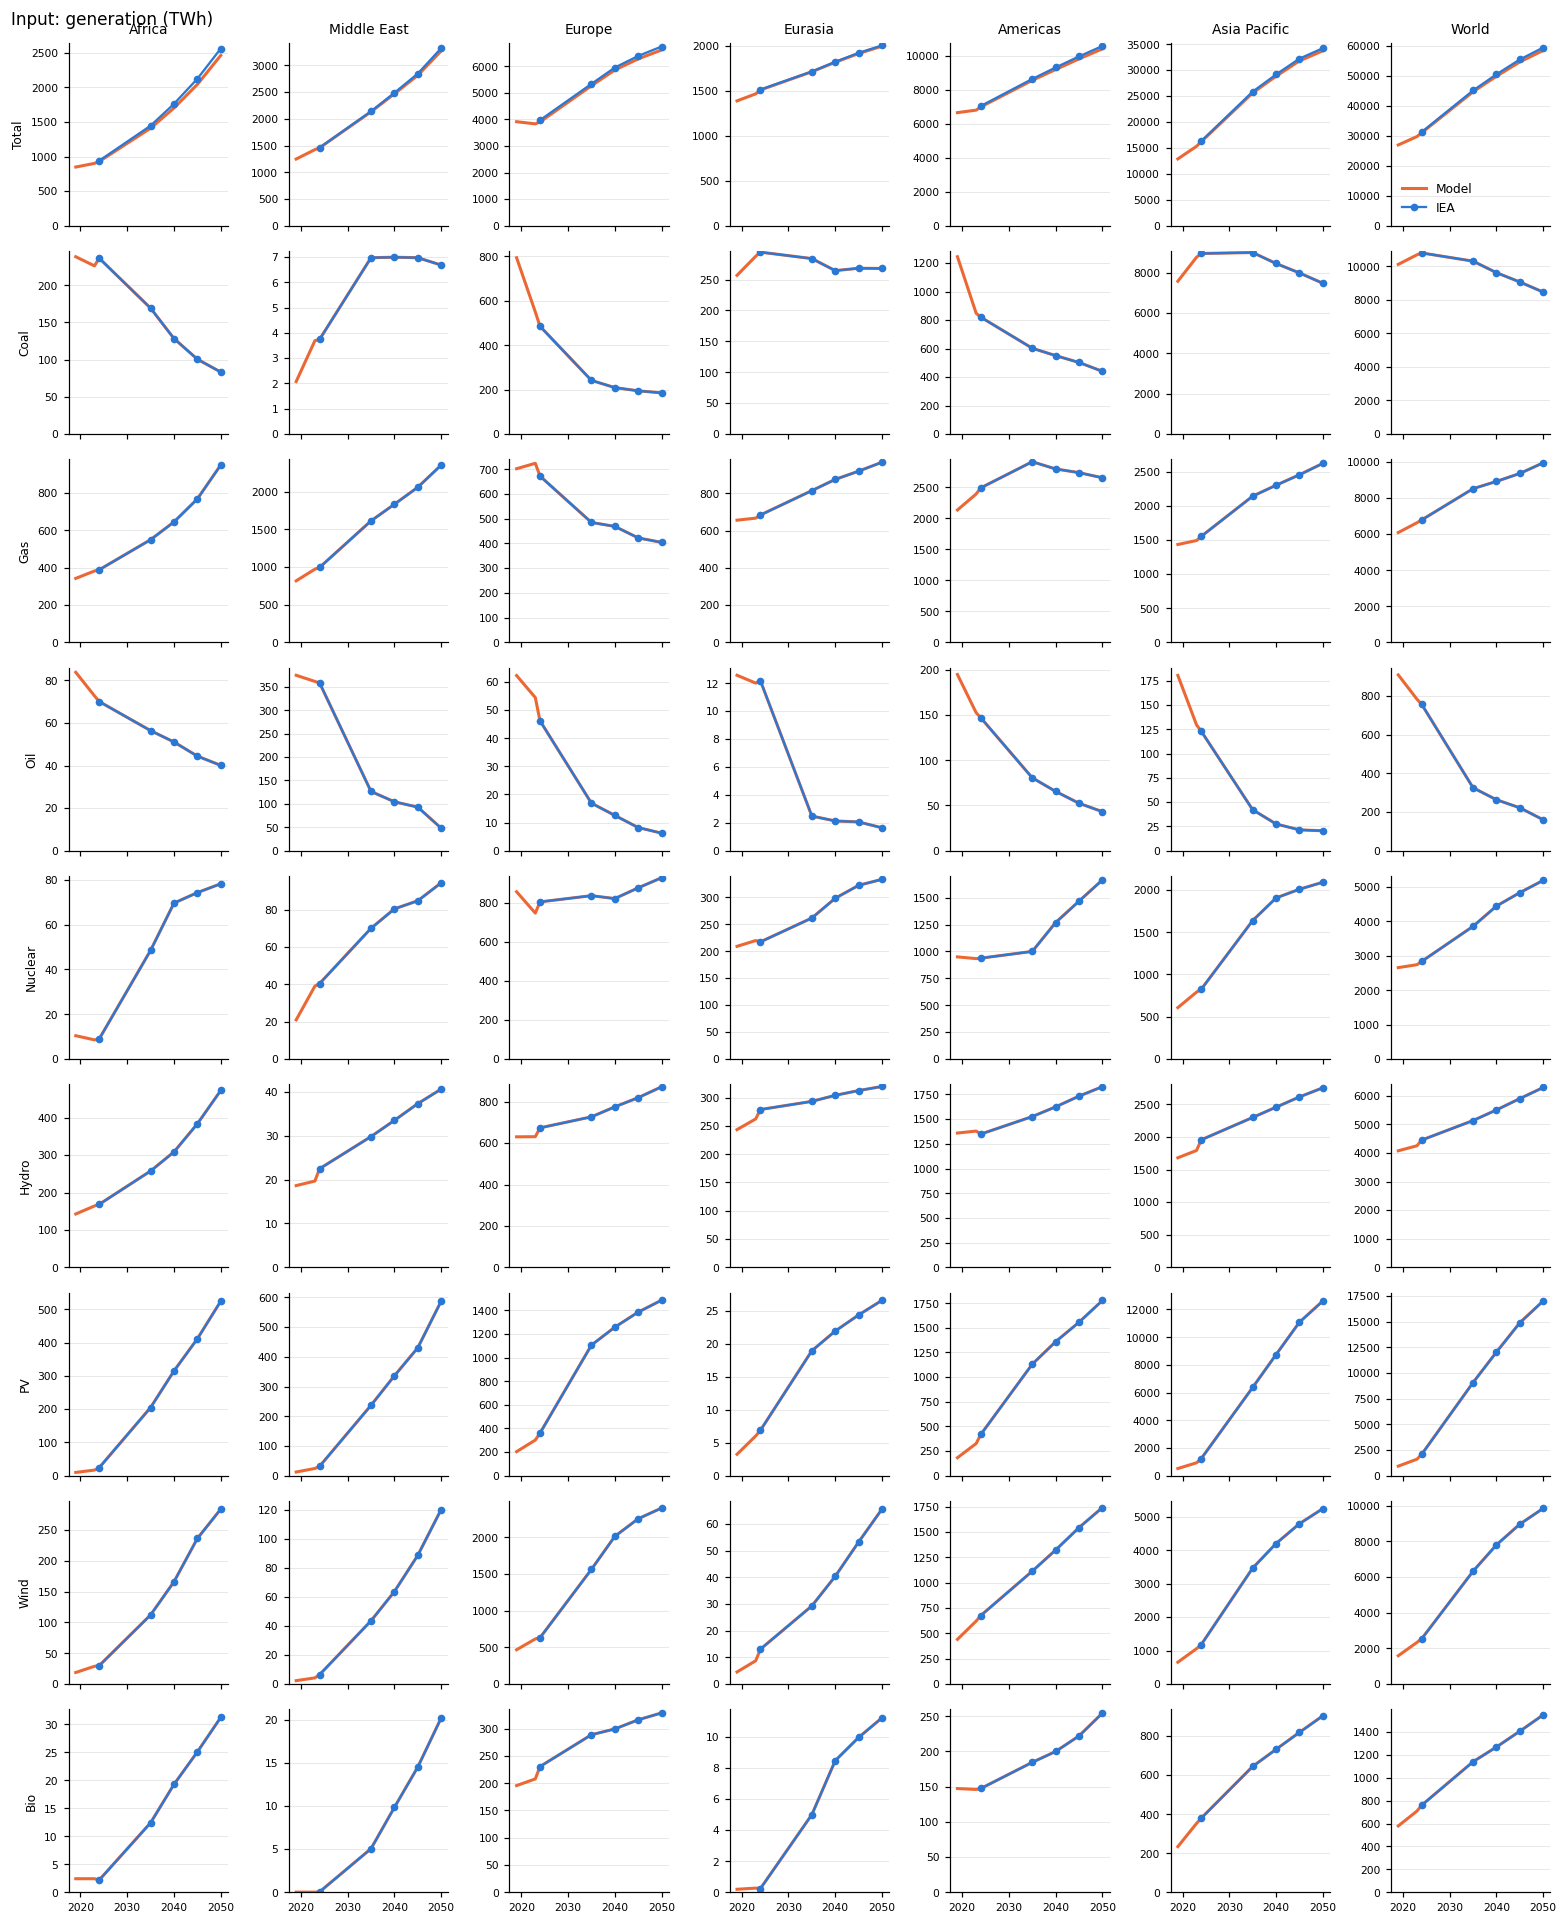

Input: generation: model / IEA


group        Africa Middle East Europe Eurasia Americas Asia Pacific World  \
item    year                                                                 
Total   2024   0.99        1.00   0.98    1.00     0.99         0.99  0.99   
        2035   0.98        1.00   0.99    1.00     0.99         0.99  0.99   
        2050   0.96        0.98   0.98    1.00     0.98         0.99  0.98   
Coal    2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2035   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2050   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
Gas     2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2035   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2050   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
Oil     2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2035   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2050   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
Nuclear 2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2035   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2050   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
Hydro   2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2035   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2050   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
PV      2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2035   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2050   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
Wind    2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2035   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2050   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
Bio     2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2035   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
        2050   1.00        1.00   1.00    1.00     1.00         1.00  1.00   

group        EAS ~ China SAS ~ India SEP ~ SE Asia  
item    year                                        
Total   2024        1.09        1.12          0.98  
        2035        1.06        1.09          0.97  
        2050        1.07        1.07          0.96  
Coal    2024        1.05        1.05          1.00  
        2035        1.03        1.03          1.00  
        2050        1.03        1.02          1.00  
Gas     2024        1.79        2.20          1.00  
        2035        1.51        2.11          1.00  
        2050        1.47        1.62          1.00  
Oil     2024        4.71        3.61          1.00  
        2035        6.55        2.00          1.00  
        2050       29.45        1.98          1.00  
Nuclear 2024        1.29        1.70                
        2035        1.19        1.27                
        2050        1.15        1.20          1.00  
Hydro   2024        1.06        1.16          1.00  
        2035        1.08        1.11          1.00  
        2050        1.13        1.13          1.00  
PV      2024        1.07        1.12          1.00  
        2035        1.04        1.05          1.00  
        2050        1.04        1.05          1.00  
Wind    2024        1.03        1.11          1.00  
        2035        1.05        1.13          1.00  
        2050        1.08        1.09          1.00  
Bio     2024        1.05        1.09          1.00  
        2035        1.09        1.11          1.00  
        2050        1.12        1.12          1.00

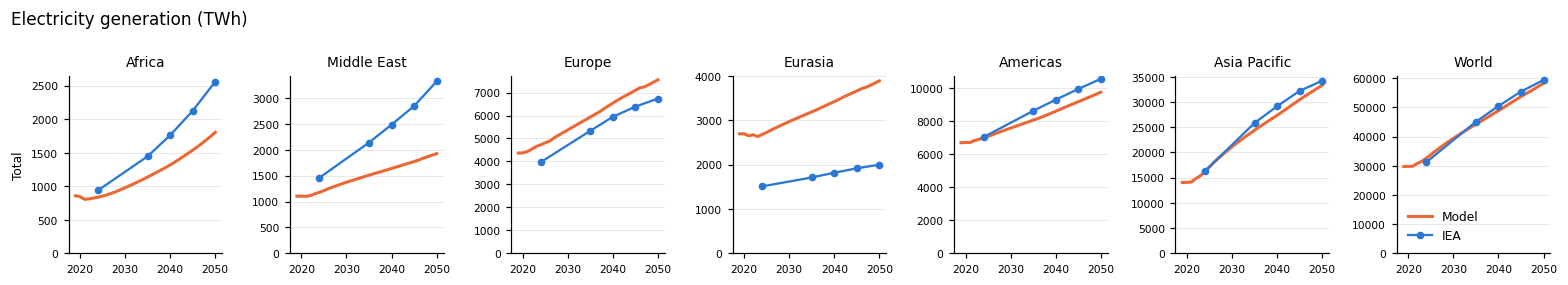

Electricity generation: model / IEA


group      Africa Middle East Europe Eurasia Americas Asia Pacific World  \
item  year                                                                 
Total 2024   0.89        0.81   1.19    1.78     0.99         0.99  1.04   
      2035   0.79        0.71   1.11    1.87     0.93         0.94  0.98   
      2050   0.70        0.58   1.12    1.94     0.92         0.97  0.98   

group      EAS ~ China SAS ~ India SEP ~ SE Asia  
item  year                                        
Total 2024        1.15        0.88          0.84  
      2035        1.08        0.81          0.77  
      2050        1.18        0.74          0.73

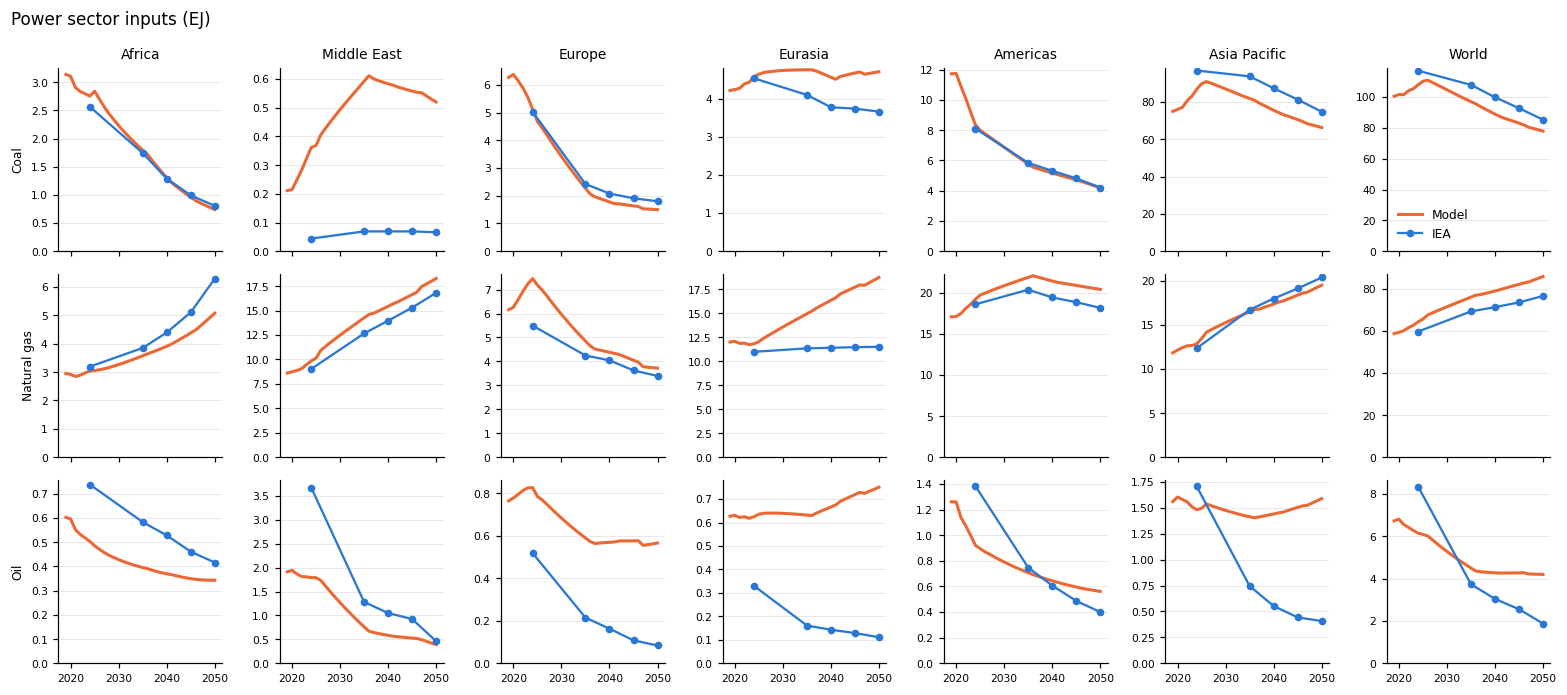

Power sector inputs: model / IEA


group            Africa Middle East Europe Eurasia Americas Asia Pacific  \
item        year                                                           
Coal        2024   1.07        8.21   1.02    1.01     1.03         0.90   
            2035   1.03        8.58   0.94    1.16     0.99         0.87   
            2050   0.92        7.88   0.83    1.29     0.99         0.89   
Natural gas 2024   0.95        1.09   1.36    1.08     1.03         1.04   
            2035   0.93        1.13   1.14    1.32     1.07         0.99   
            2050   0.81        1.09   1.10    1.63     1.12         0.96   
Oil         2024   0.68        0.49   1.59    1.89     0.67         0.87   
            2035   0.68        0.59   2.74    3.92     0.95         1.90   
            2050   0.82        0.85   6.74    6.76     1.40         3.89   

group            World EAS ~ China SAS ~ India SEP ~ SE Asia  
item        year                                              
Coal        2024  0.92        0.92        0.95          1.00  
            2035  0.90        0.86        0.98          0.90  
            2050  0.91        0.93        0.92          0.76  
Natural gas 2024  1.08        1.63        3.37          1.00  
            2035  1.10        1.16        3.46          0.98  
            2050  1.12        1.06        2.66          0.85  
Oil         2024  0.74        1.16        6.58          1.51  
            2035  1.21        2.00        7.76          2.57  
            2050  2.24        3.51       23.76          2.73

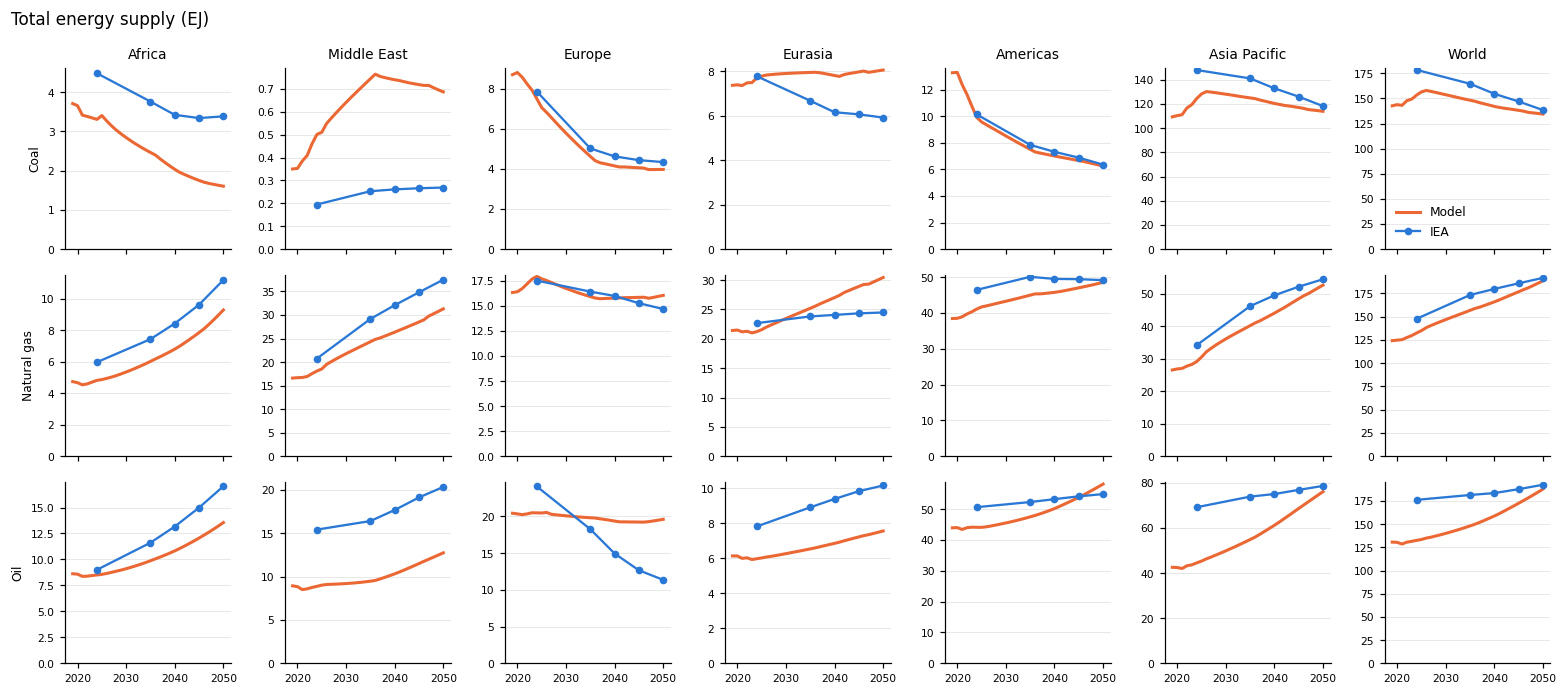

Total energy supply: model / IEA


group            Africa Middle East Europe Eurasia Americas Asia Pacific  \
item        year                                                           
Coal        2024   0.74        2.57   0.95    0.99     0.98         0.84   
            2035   0.66        2.94   0.92    1.19     0.96         0.89   
            2050   0.47        2.55   0.92    1.36     0.98         0.96   
Natural gas 2024   0.81        0.87   1.02    0.94     0.88         0.85   
            2035   0.81        0.83   0.97    1.06     0.90         0.87   
            2050   0.83        0.83   1.09    1.24     0.99         0.97   
Oil         2024   0.94        0.58   0.85    0.76     0.87         0.64   
            2035   0.85        0.58   1.09    0.73     0.91         0.74   
            2050   0.80        0.63   1.73    0.74     1.06         0.97   

group            World EAS ~ China SAS ~ India SEP ~ SE Asia  
item        year                                              
Coal        2024  0.86        0.88        0.76          0.96  
            2035  0.90        0.97        0.69          0.89  
            2050  0.97        1.21        0.60          0.79  
Natural gas 2024  0.90        1.11        1.35          0.72  
            2035  0.90        1.09        0.97          0.78  
            2050  0.98        1.25        0.96          0.85  
Oil         2024  0.75        0.65        0.77          0.83  
            2035  0.82        0.85        0.86          0.76  
            2050  0.98        1.36        1.06          0.80

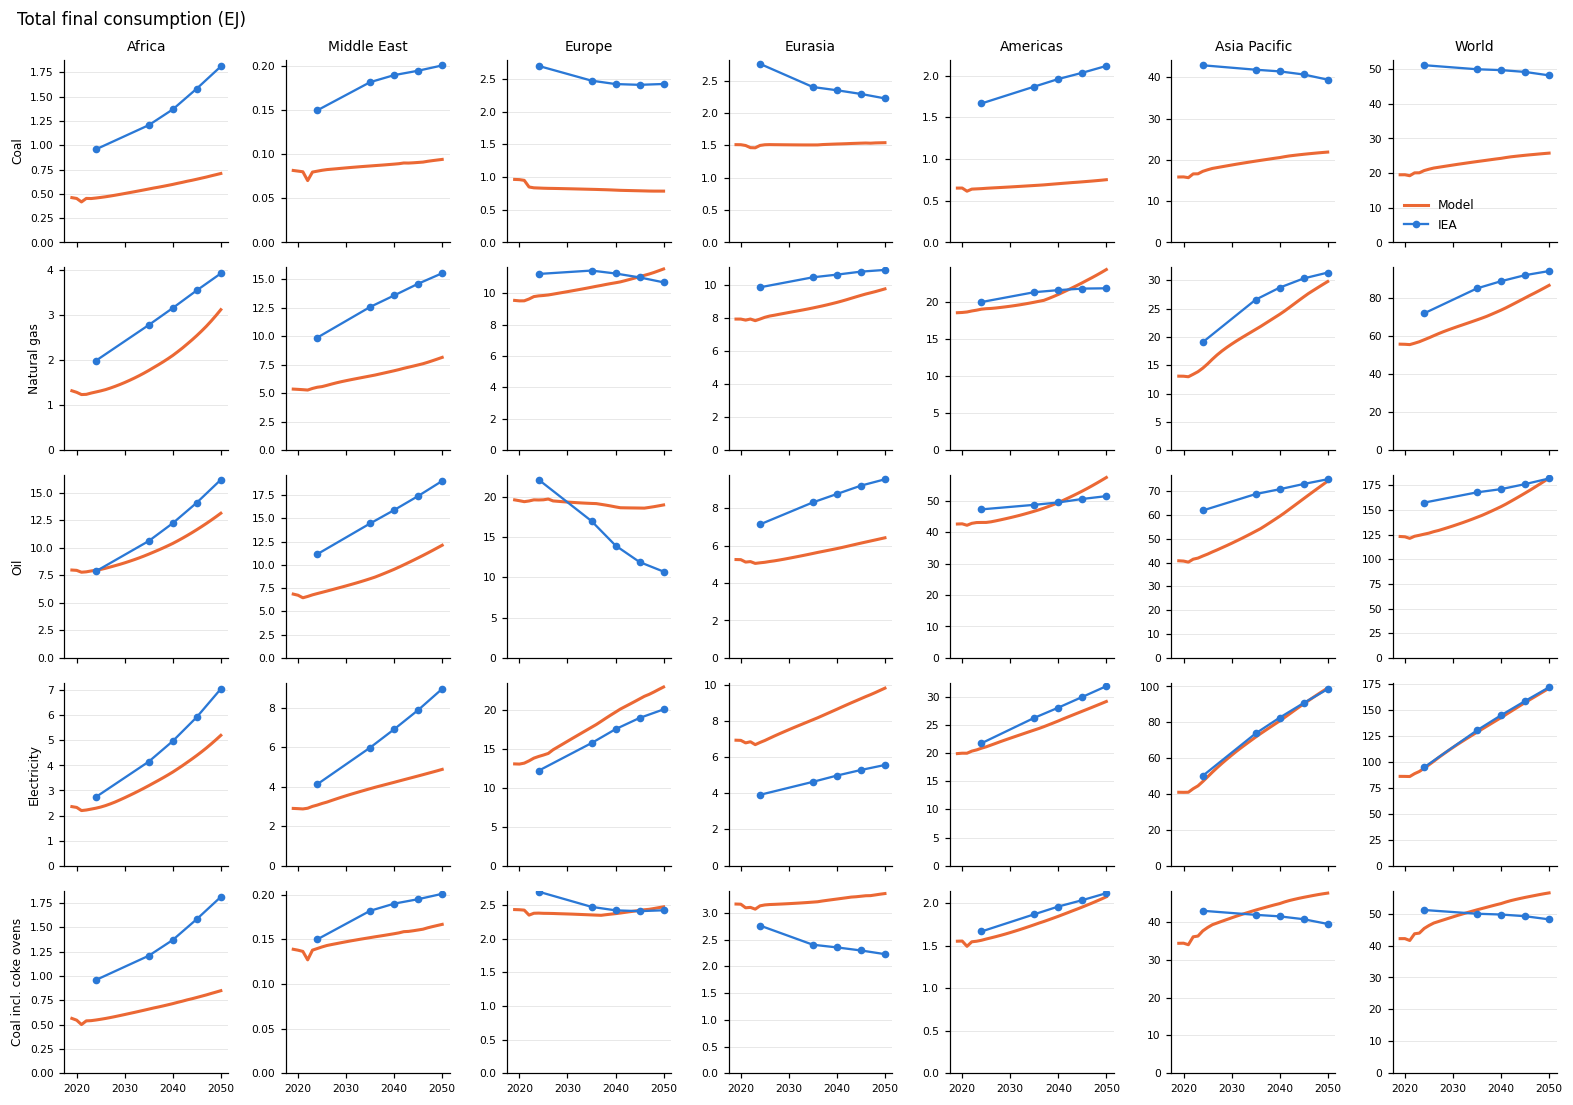

Total final consumption: model / IEA


group                      Africa Middle East Europe Eurasia Americas  \
item                  year                                              
Coal                  2024   0.48        0.54   0.31    0.54     0.39   
                      2035   0.46        0.48   0.33    0.63     0.37   
                      2050   0.39        0.47   0.32    0.69     0.36   
Natural gas           2024   0.65        0.56   0.88    0.81     0.95   
                      2035   0.64        0.52   0.91    0.82     0.94   
                      2050   0.80        0.52   1.08    0.89     1.12   
Oil                   2024   1.01        0.62   0.89    0.71     0.91   
                      2035   0.89        0.59   1.13    0.67     0.96   
                      2050   0.81        0.64   1.77    0.67     1.12   
Electricity           2024   0.84        0.74   1.15    1.74     0.96   
                      2035   0.77        0.65   1.13    1.74     0.92   
                      2050   0.74        0.54   1.14    1.76     0.91   
Coal incl. coke ovens 2024   0.57        0.93   0.88    1.13     0.94   
                      2035   0.55        0.83   0.95    1.33     0.93   
                      2050   0.47        0.83   1.02    1.51     0.98   

group                      Asia Pacific World EAS ~ China SAS ~ India  \
item                  year                                              
Coal                  2024         0.40  0.41        0.43        0.27   
                      2035         0.47  0.47        0.58        0.25   
                      2050         0.56  0.53        0.83        0.25   
Natural gas           2024         0.76  0.81        0.97        0.66   
                      2035         0.80  0.81        1.06        0.54   
                      2050         0.95  0.92        1.32        0.58   
Oil                   2024         0.69  0.80        0.69        0.88   
                      2035         0.77  0.85        0.87        0.94   
                      2050         0.99  1.00        1.36        1.12   
Electricity           2024         0.94  0.99        1.11        0.74   
                      2035         0.97  0.99        1.18        0.69   
                      2050         1.01  0.99        1.28        0.66   
Coal incl. coke ovens 2024         0.88  0.89        1.05        0.27   
                      2035         1.03  1.02        1.46        0.24   
                      2050         1.21  1.17        2.13        0.24   

group                      SEP ~ SE Asia  
item                  year                
Coal                  2024          0.87  
                      2035          0.82  
                      2050          0.79  
Natural gas           2024          0.41  
                      2035          0.48  
                      2050          0.67  
Oil                   2024          0.87  
                      2035          0.78  
                      2050          0.81  
Electricity           2024          0.74  
                      2035          0.71  
                      2050          0.69  
Coal incl. coke ovens 2024          0.99  
                      2035          0.95  
                      2050          0.94

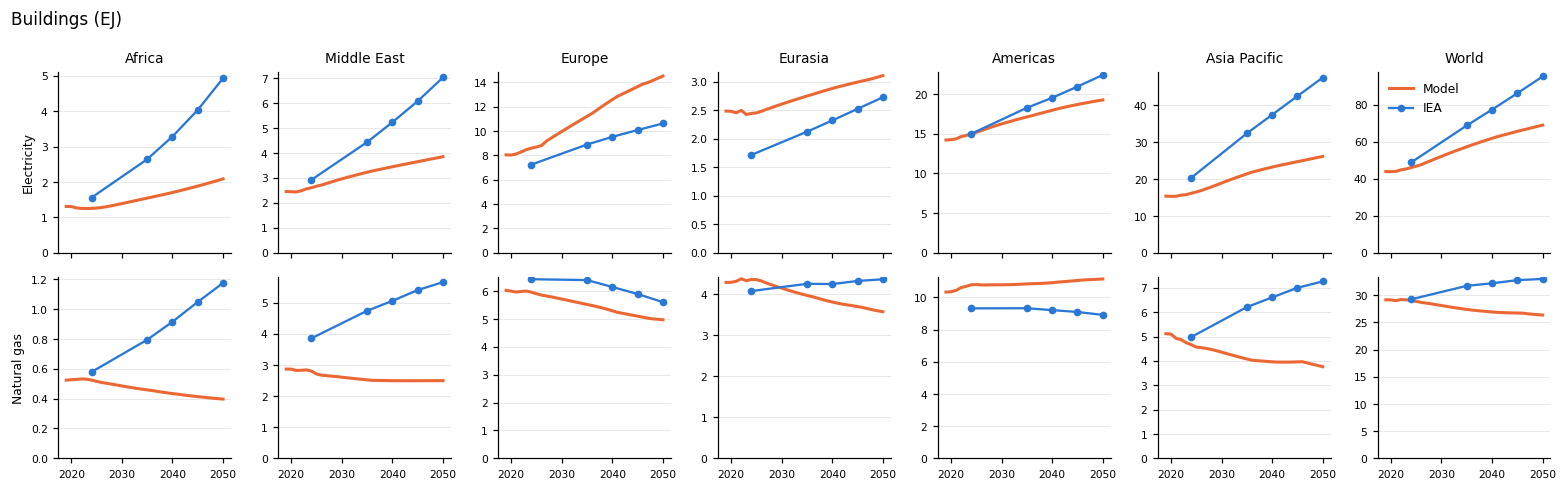

Buildings: model / IEA


group            Africa Middle East Europe Eurasia Americas Asia Pacific  \
item        year                                                           
Electricity 2024   0.81        0.89   1.19    1.42     1.00         0.79   
            2035   0.58        0.73   1.26    1.29     0.94         0.66   
            2050   0.42        0.55   1.37    1.14     0.86         0.55   
Natural gas 2024   0.91        0.73   0.93    1.07     1.16         0.94   
            2035   0.58        0.53   0.86    0.93     1.16         0.66   
            2050   0.34        0.44   0.89    0.82     1.25         0.52   

group            World EAS ~ China SAS ~ India SEP ~ SE Asia  
item        year                                              
Electricity 2024  0.94        0.85        0.89          0.84  
            2035  0.83        0.69        0.67          0.70  
            2050  0.72        0.60        0.49          0.55  
Natural gas 2024  1.00        1.01       13.15          6.79  
            2035  0.86        0.67        3.21          1.72  
            2050  0.80        0.52        1.57          1.00

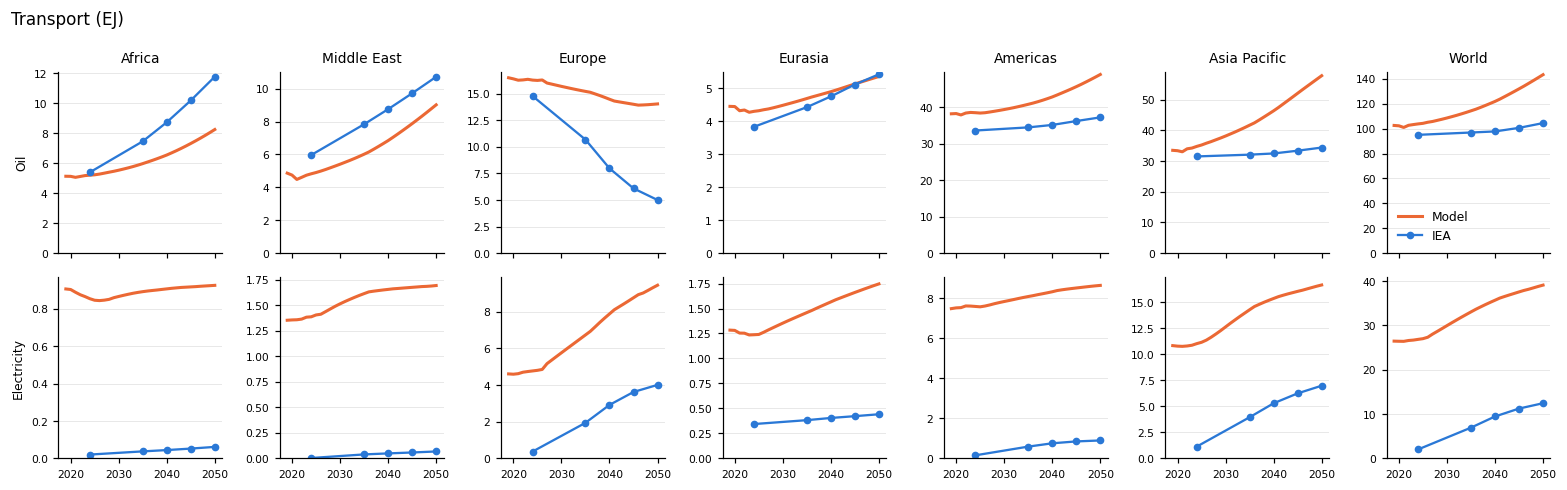

Transport: model / IEA


group            Africa Middle East Europe Eurasia Americas Asia Pacific  \
item        year                                                           
Oil         2024   0.96        0.81   1.10    1.12     1.15         1.10   
            2035   0.80        0.77   1.43    1.06     1.18         1.30   
            2050   0.70        0.84   2.81    0.99     1.32         1.68   
Electricity 2024  42.68      462.15  12.91    3.61    51.00         9.80   
            2035  24.09       42.47   3.48    3.82    13.84         3.62   
            2050  15.16       25.27   2.36    3.96     9.69         2.39   

group             World EAS ~ China SAS ~ India SEP ~ SE Asia  
item        year                                               
Oil         2024   1.09        1.21        1.44          1.17  
            2035   1.18        2.05        1.41          1.00  
            2050   1.37        4.85        1.63          1.01  
Electricity 2024  13.38        8.07       12.88         46.28  
            2035   4.78        2.90        6.23         13.20  
            2050   3.14        1.92        3.86          7.09

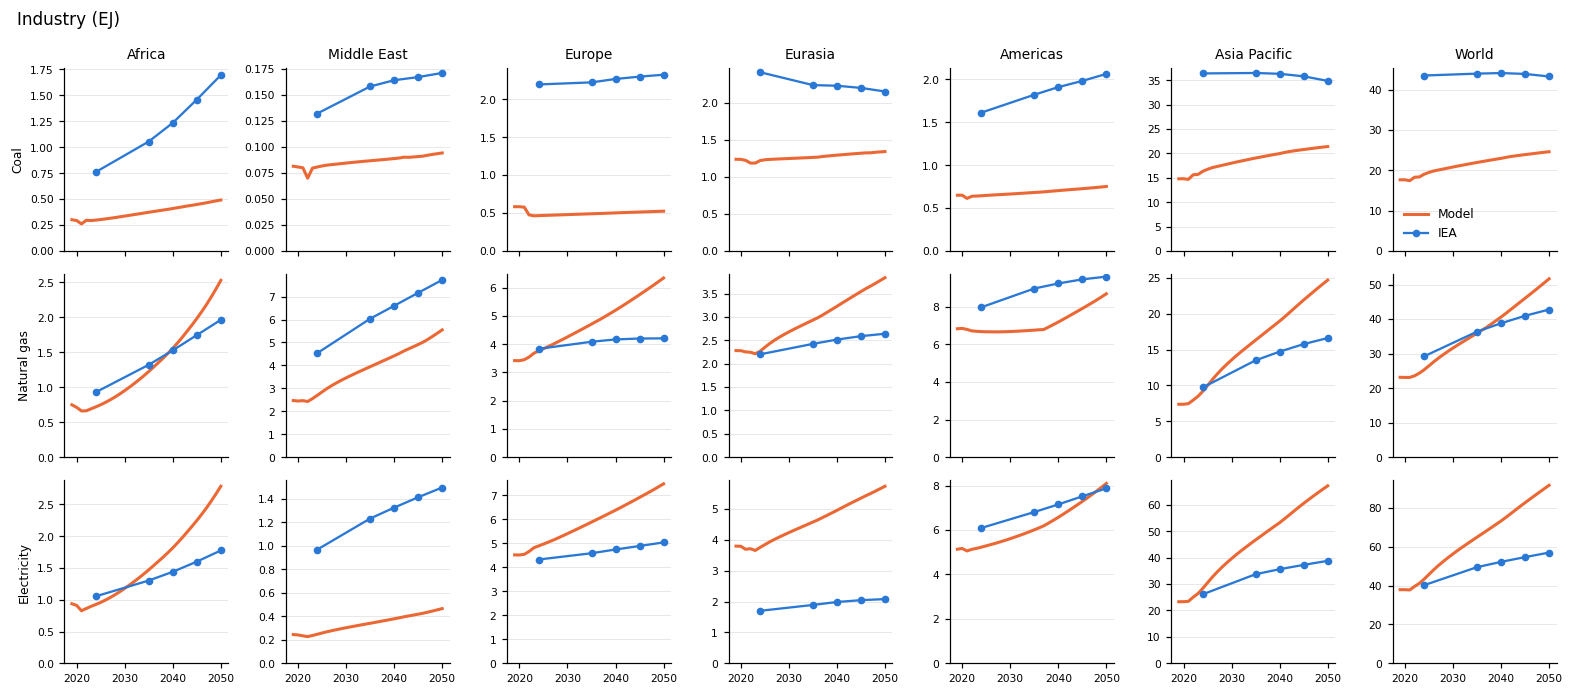

Industry: model / IEA


group            Africa Middle East Europe Eurasia Americas Asia Pacific  \
item        year                                                           
Coal        2024   0.39        0.61   0.21    0.51     0.40         0.45   
            2035   0.35        0.55   0.22    0.56     0.37         0.52   
            2050   0.29        0.55   0.23    0.62     0.36         0.61   
Natural gas 2024   0.77        0.59   0.98    1.03     0.84         0.94   
            2035   0.93        0.65   1.15    1.21     0.75         1.21   
            2050   1.29        0.72   1.51    1.45     0.90         1.49   
Electricity 2024   0.88        0.26   1.13    2.21     0.86         1.09   
            2035   1.13        0.28   1.28    2.42     0.88         1.39   
            2050   1.57        0.31   1.48    2.76     1.03         1.73   

group            World EAS ~ China SAS ~ India SEP ~ SE Asia  
item        year                                              
Coal        2024  0.44        0.51        0.25          0.87  
            2035  0.50        0.69        0.24          0.82  
            2050  0.57        1.05        0.24          0.79  
Natural gas 2024  0.87        1.15        0.95          0.53  
            2035  0.99        1.56        0.90          0.64  
            2050  1.21        2.03        0.91          0.92  
Electricity 2024  1.08        1.33        0.51          0.63  
            2035  1.31        1.73        0.69          0.74  
            2050  1.61        2.23        0.87          0.98

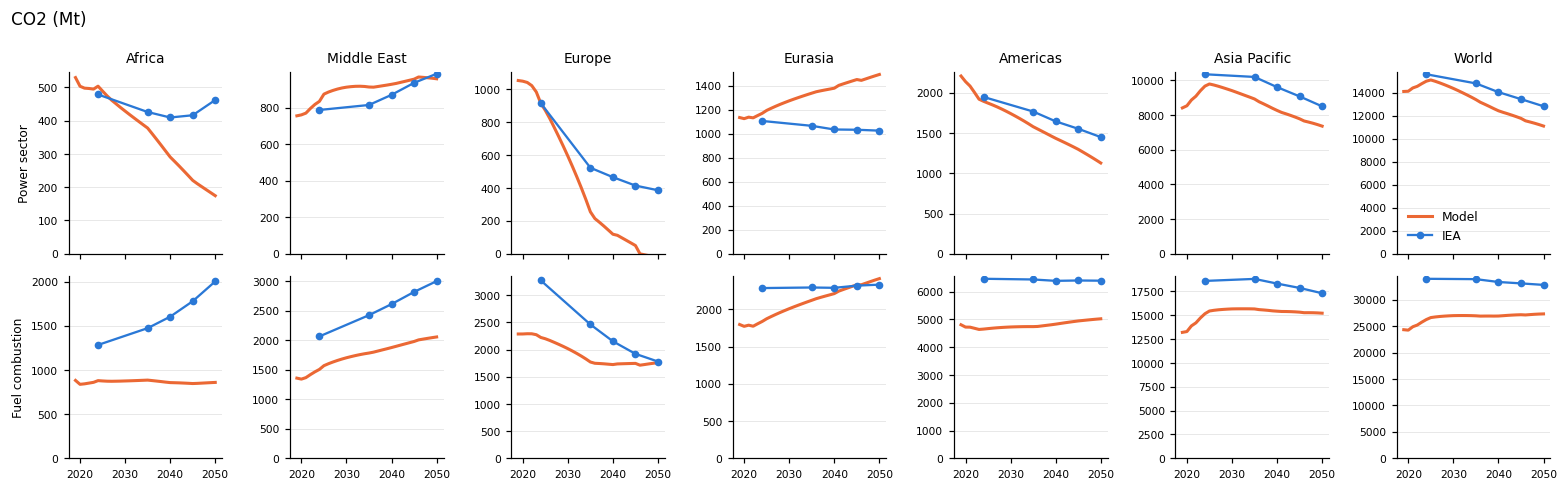

CO2: model / IEA


group                Africa Middle East Europe Eurasia Americas Asia Pacific  \
item            year                                                           
Power sector    2024   1.05        1.06   1.00    1.06     0.97         0.93   
                2035   0.89        1.12   0.49    1.26     0.89         0.88   
                2050   0.38        0.97  -0.06    1.46     0.78         0.87   
Fuel combustion 2024   0.69        0.73   0.68    0.80     0.72         0.82   
                2035   0.60        0.74   0.72    0.93     0.74         0.83   
                2050   0.43        0.68   0.99    1.03     0.79         0.88   

group                World EAS ~ China SAS ~ India SEP ~ SE Asia  
item            year                                              
Power sector    2024  0.96        0.94        1.11          1.04  
                2035  0.90        0.86        1.08          0.91  
                2050  0.87        0.90        1.06          0.76  
Fuel combustion 2024  0.77        0.88        0.85          0.89  
                2035  0.80        0.94        0.76          0.84  
                2050  0.83        1.14        0.70          0.76

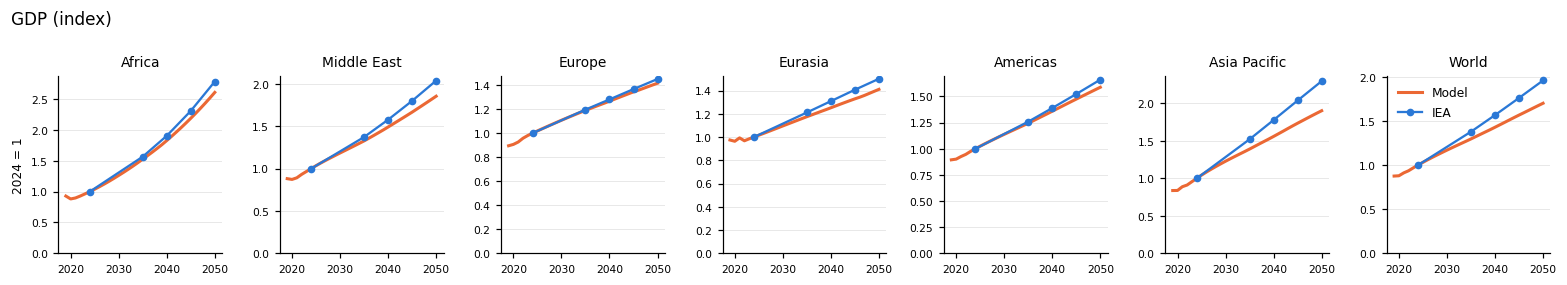

GDP: model / IEA


group         Africa Middle East Europe Eurasia Americas Asia Pacific World  \
item     year                                                                 
2024 = 1 2024   1.00        1.00   1.00    1.00     1.00         1.00  1.00   
         2035   0.97        0.97   1.00    0.97     0.99         0.91  0.94   
         2050   0.94        0.91   0.98    0.94     0.96         0.83  0.87   

group         EAS ~ China SAS ~ India SEP ~ SE Asia  
item     year                                        
2024 = 1 2024        1.00        1.00          1.00  
         2035        0.95        0.91          0.96  
         2050        0.91        0.81          0.93

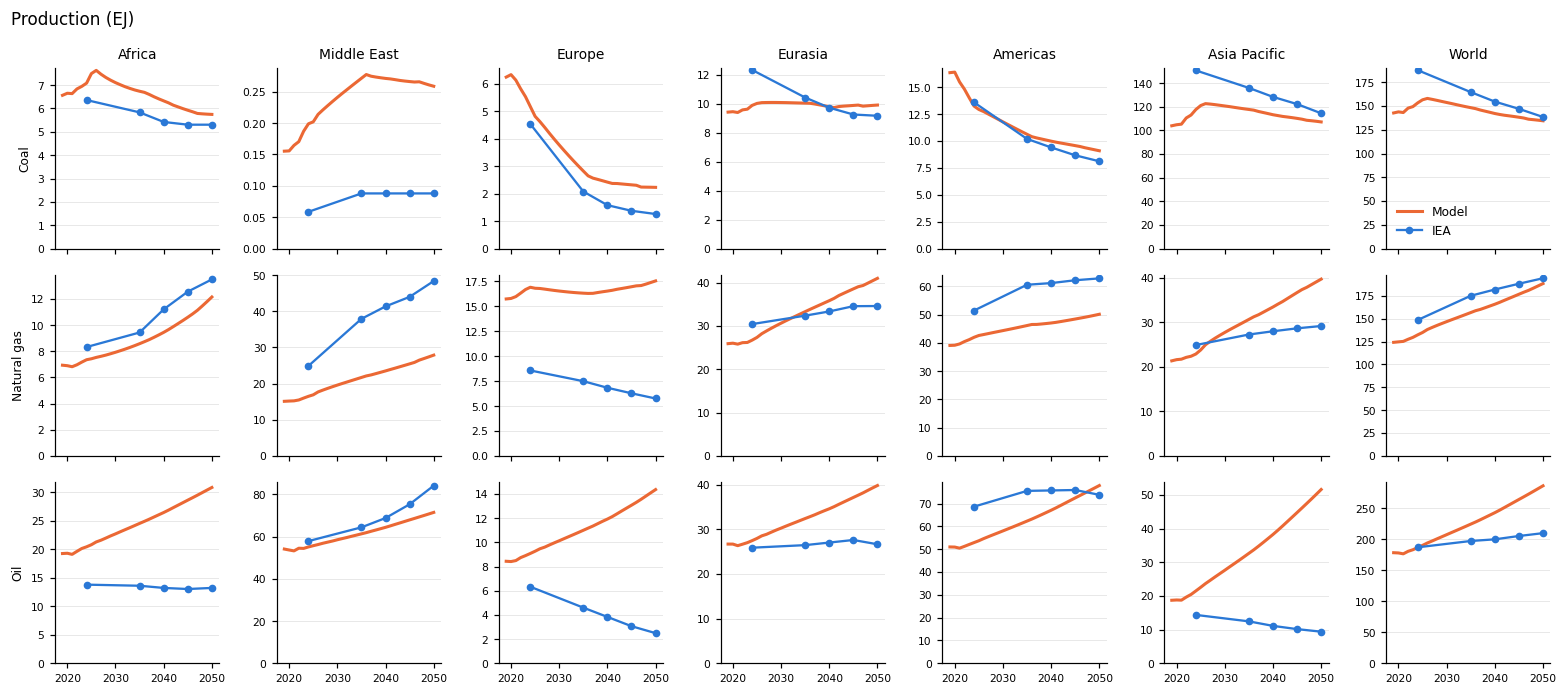

Production: model / IEA


group            Africa Middle East Europe Eurasia Americas Asia Pacific  \
item        year                                                           
Coal        2024   1.11        3.39   1.14    0.80     0.97         0.78   
            2035   1.16        3.09   1.36    0.96     1.04         0.87   
            2050   1.08        2.94   1.77    1.08     1.12         0.94   
Natural gas 2024   0.88        0.66   1.97    0.88     0.82         0.92   
            2035   0.91        0.57   2.18    1.03     0.76         1.12   
            2050   0.90        0.58   3.05    1.18     0.80         1.36   
Oil         2024   1.48        0.95   1.43    1.06     0.77         1.50   
            2035   1.80        0.95   2.39    1.23     0.82         2.62   
            2050   2.33        0.85   5.76    1.49     1.06         5.50   

group            World EAS ~ China SAS ~ India SEP ~ SE Asia  
item        year                                              
Coal        2024  0.82        0.85        0.39          0.47  
            2035  0.90        0.96        0.35          0.64  
            2050  0.97        1.16        0.31          0.67  
Natural gas 2024  0.89        0.85        2.06          0.86  
            2035  0.90        0.80        1.79          1.36  
            2050  0.97        1.03        1.79          1.60  
Oil         2024  1.00        1.23        2.26          2.19  
            2035  1.14        2.24        4.02          3.28  
            2050  1.36        4.89        8.98          5.73

In [12]:
def grid(indicator):
    d = cmp[cmp['indicator'] == indicator]; items = list(d['item'].unique()); cols = list(GROUPS) + ['World']
    fig, axes = plt.subplots(len(items), len(cols), figsize=(2.05 * len(cols), 1.9 * len(items) + 0.7), squeeze=False, sharex=True)
    for i, it in enumerate(items):
        for j, gname in enumerate(cols):
            ax = axes[i, j]; s = d[(d['item'] == it) & (d['group'] == gname)].sort_values('year')
            m = s.dropna(subset=['model']); t = s.dropna(subset=['IEA'])
            ax.plot(m['year'], m['model'], color=C_MODEL, lw=2, label='Model')
            ax.plot(t['year'], t['IEA'], color=C_IEA, lw=1.5, marker='o', ms=4, label='IEA')
            ax.set_ylim(bottom=0); ax.tick_params(labelsize=7); ax.grid(axis='y', color='#e6e6e6', lw=0.6)
            if i == 0: ax.set_title(gname, fontsize=9)
            if j == 0: ax.set_ylabel(it, fontsize=8)
    axes[0, -1].legend(frameon=False, fontsize=8)
    fig.suptitle(f"{indicator} ({d['unit'].iloc[0]})", x=0.01, ha='left', fontsize=11); fig.tight_layout(); save(fig, f'7_3 {indicator}'); plt.show()
    t = d[d['year'].isin([2024, 2035, 2050])].pivot(index=['item', 'year'], columns='group', values='ratio').reindex(columns=order).reindex(items, level=0)
    show(t, f'{indicator}: model / IEA', '{:.2f}')

for k in cmp['indicator'].unique(): grid(k)

### 7.4 Scorecard

Model divided by IEA. White: equal. Red: model above IEA. Blue: model below. Colour runs from one third to three times.

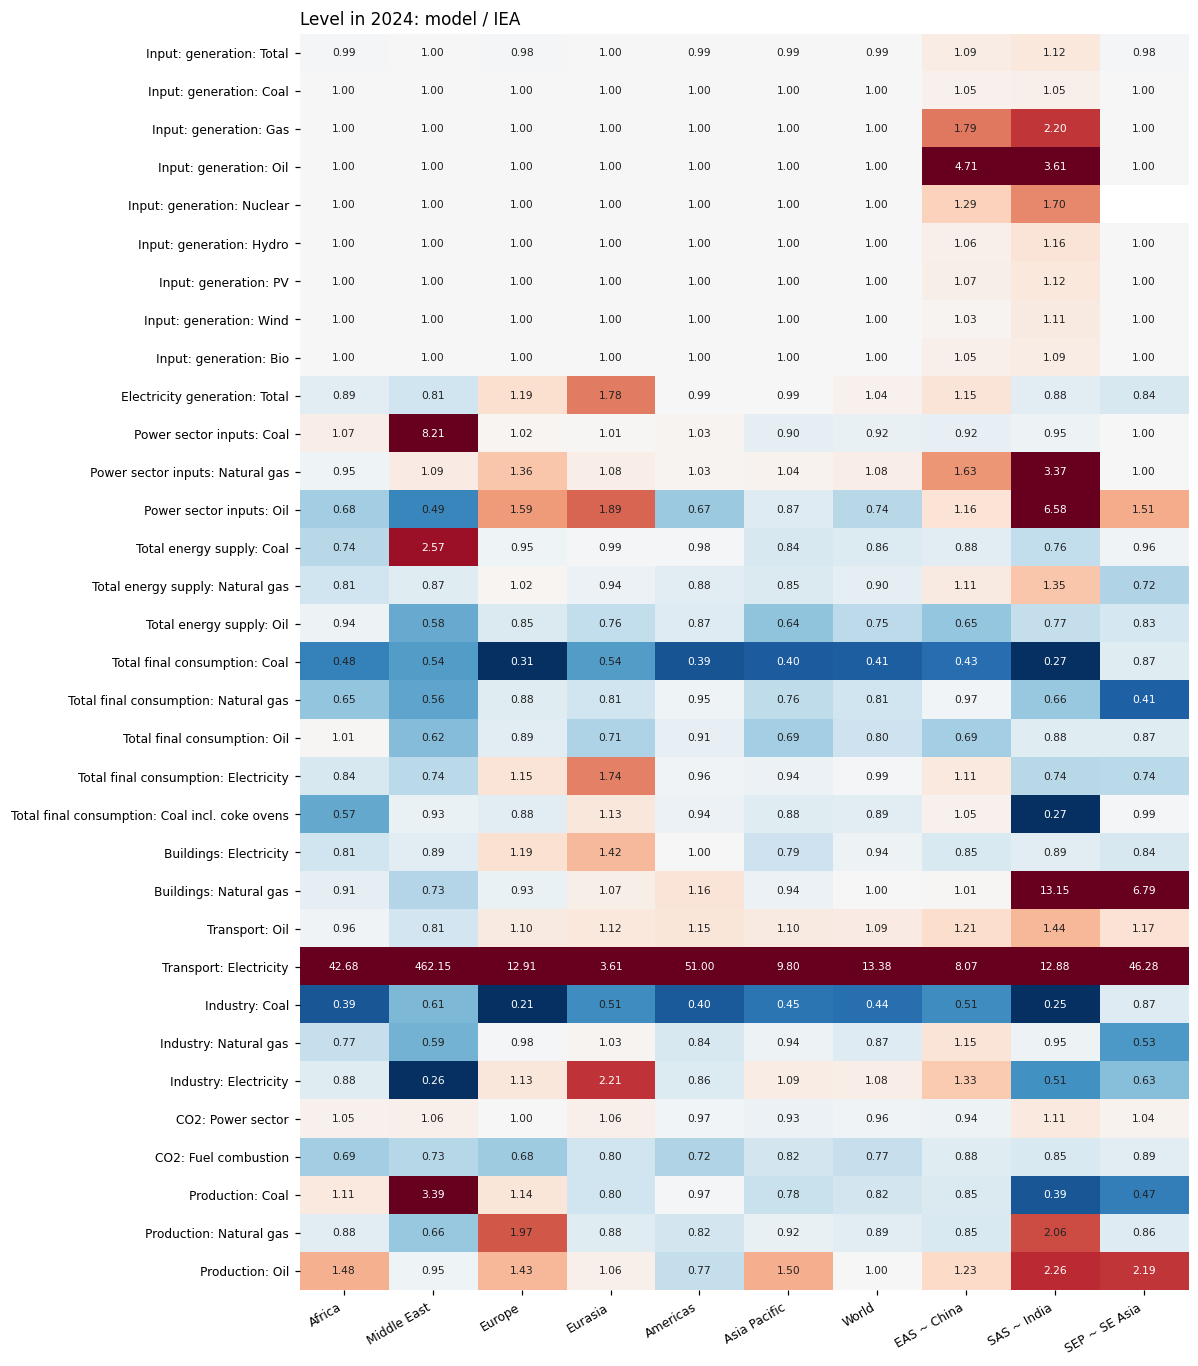

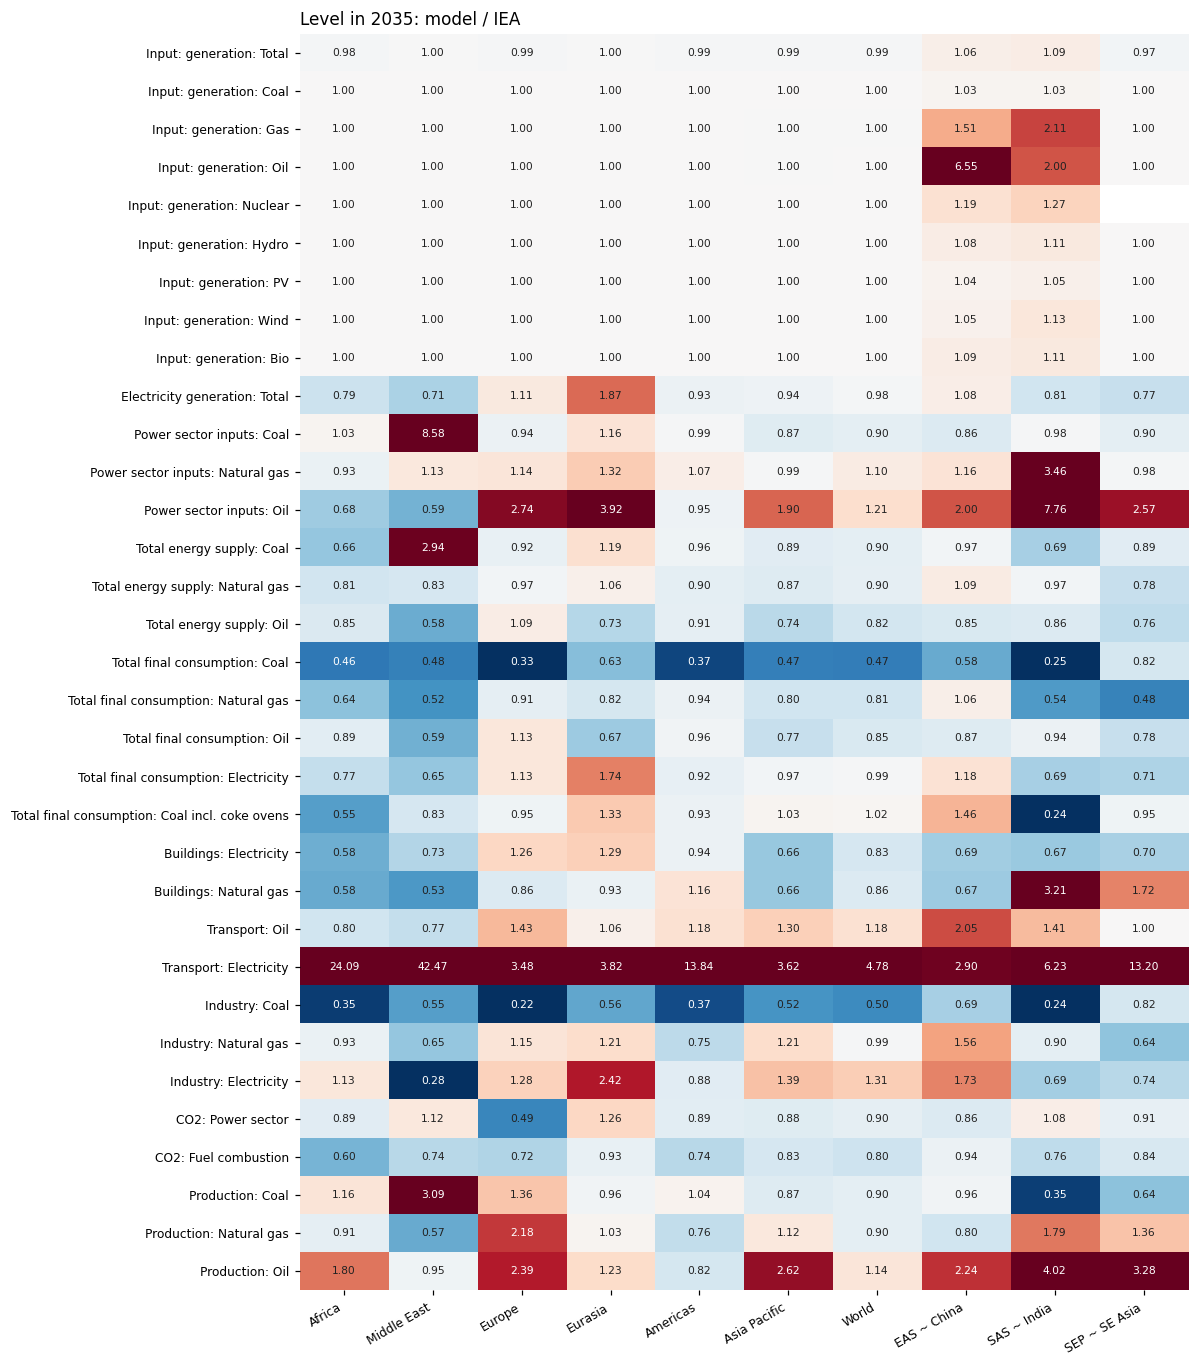

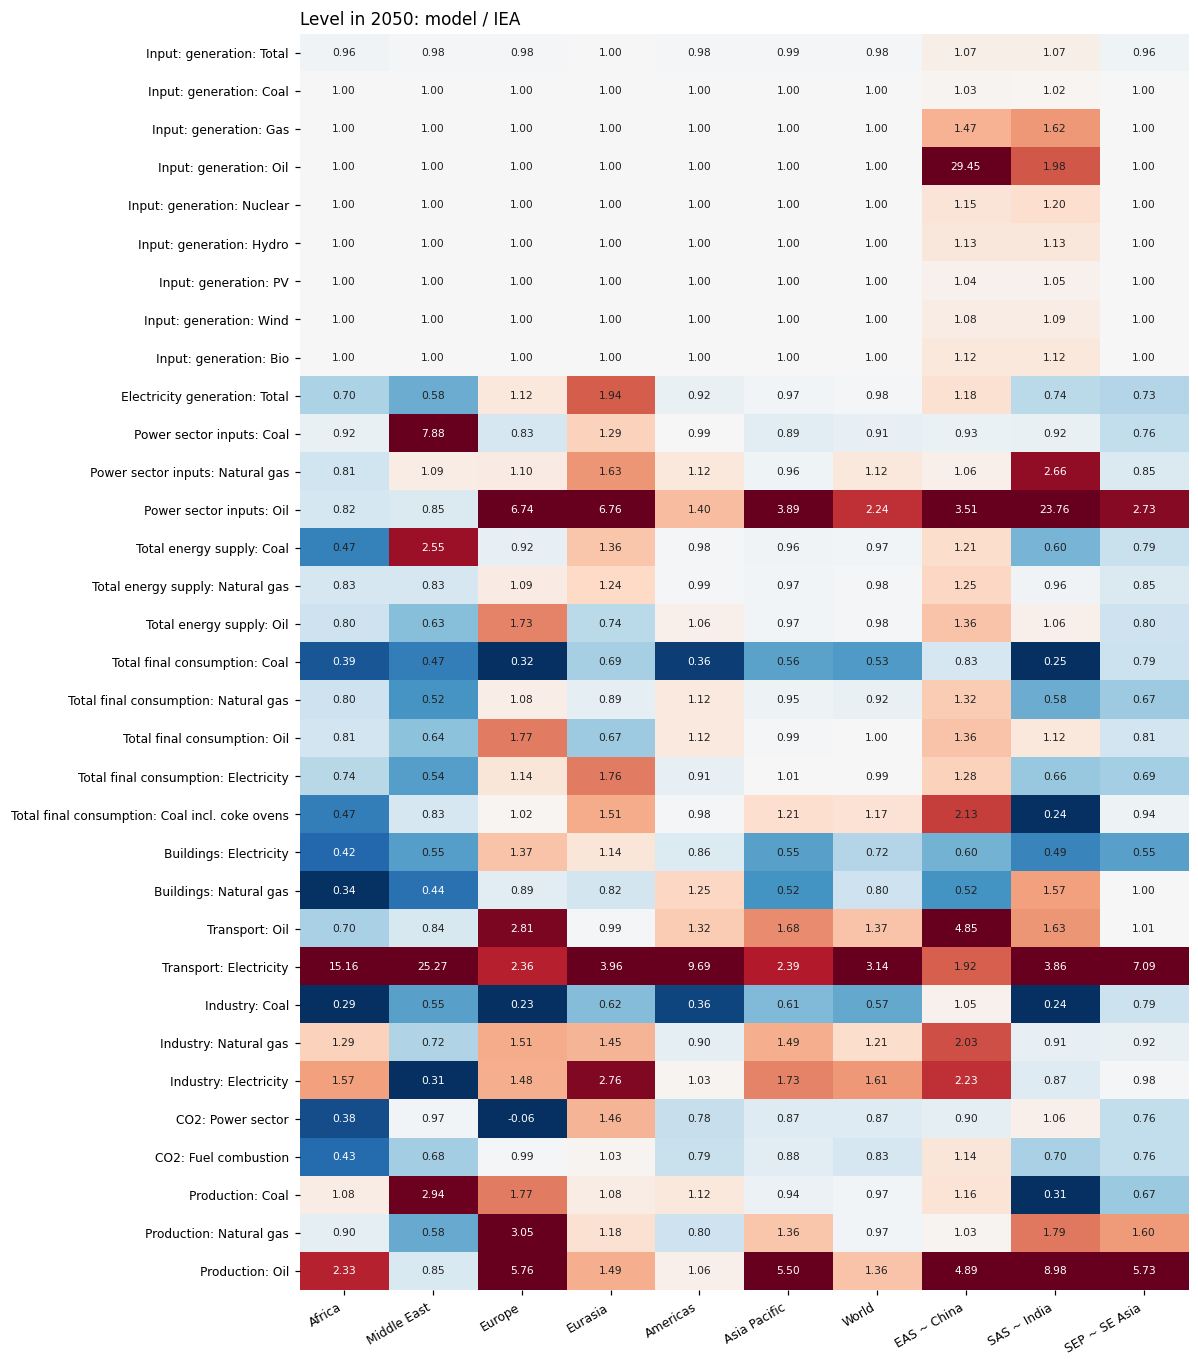

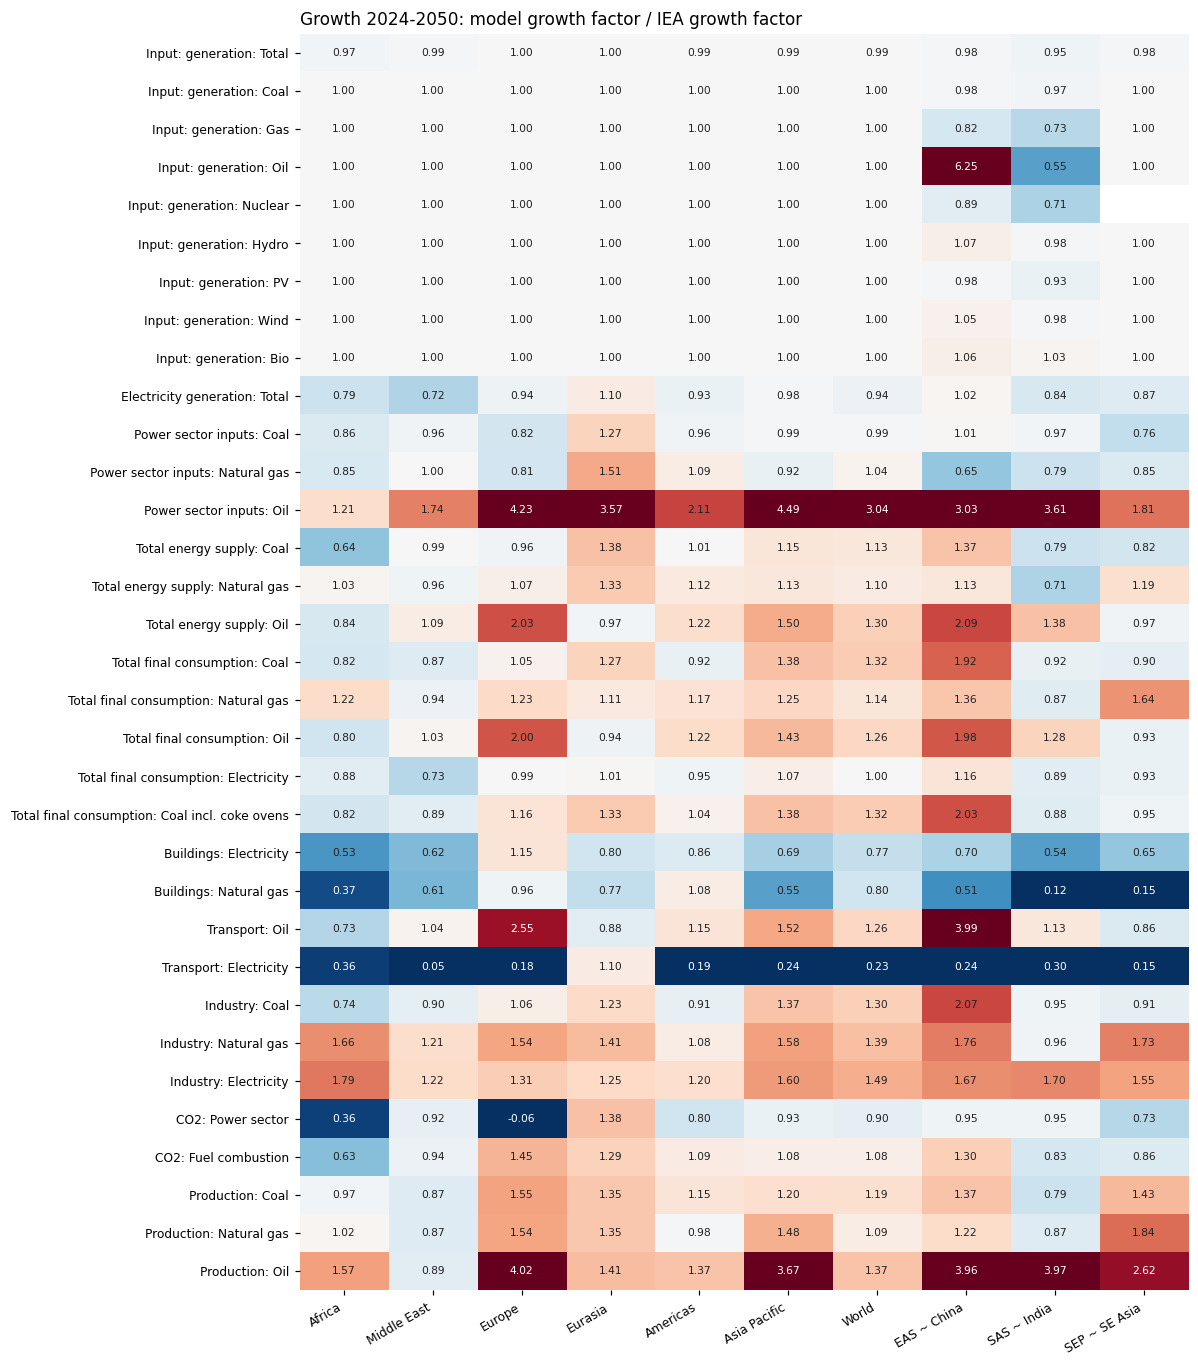

In [13]:
def heat(t, title):
    t = t.reindex(columns=order); v = np.log2(t.astype(float).clip(lower=1e-3).values)
    fig, ax = plt.subplots(figsize=(11, 0.34 * len(t) + 1.3))
    ax.imshow(np.ma.masked_invalid(v), cmap='RdBu_r', vmin=-1.585, vmax=1.585, aspect='auto')
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=8, rotation=30, ha='right')
    ax.set_yticks(range(t.shape[0])); ax.set_yticklabels([f'{a}: {b}' for a, b in t.index], fontsize=8)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            x = t.iat[i, j]
            if pd.notna(x): ax.text(j, i, f'{x:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(v[i, j]) > 1.1 else '#222222')
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_title(title, loc='left', fontsize=11); fig.tight_layout(); save(fig, '7_4 ' + title.split(':')[0]); plt.show()

keep = cmp[cmp['indicator'] != 'GDP']
piv = lambda y, col: keep[keep['year'] == y].pivot(index=['indicator', 'item'], columns='group', values=col).reindex(keep[['indicator', 'item']].drop_duplicates().apply(tuple, axis=1))
heat(piv(2024, 'ratio'), 'Level in 2024: model / IEA')
heat(piv(2035, 'ratio'), 'Level in 2035: model / IEA')
heat(piv(2050, 'ratio'), 'Level in 2050: model / IEA')
heat((piv(2050, 'model') / piv(2024, 'model')) / (piv(2050, 'IEA') / piv(2024, 'IEA')), 'Growth 2024-2050: model growth factor / IEA growth factor')
cmp.to_csv(os.path.join(FIG_DIR, 'iea_comparison.csv'), index=False)